# Predicting Student Dropout and Academic Success

**IT5022 Fundamentals of Machine Learning · Group Assignment (group of 2)**

| Member | Registration | Owns, as set out in the project plan |
|---|---|---|
| Kusal Dissanayake | MS26929064 | Preprocessing and feature screening; Random Forest and the decision trees behind it; PCA |
| Lahiru Sandeepa | MS26929378 | Linear Regression; SMOTE, the threshold sweep and ROC/PR analysis |



---

### Problem statement
Student dropout is costly for universities and students alike. Using information available at enrolment and after the
first two semesters, we predict whether a student will **Graduate**, remain **Enrolled**, or **Drop out** — a
**supervised, 3-class classification** problem that can power an early-warning / student-support system.

### Dataset
- **Name:** Predict Students' Dropout and Academic Success
- **Source:** UCI Machine Learning Repository, dataset **#697** — https://archive.ics.uci.edu/dataset/697 (DOI 10.24432/C5MC89)
- **Size:** 4,424 students · 36 features · target `{Dropout, Enrolled, Graduate}`
- **Features:** demographics (marital status, nationality, gender, age), socio-economic context (parents'
  qualifications/occupations, tuition fees up to date, scholarship holder, debtor), academic background (application
  mode, previous/admission grade) and **curricular-unit performance in semesters 1 & 2**

## 1. Imports · *Lahiru*

In [1]:
# Core libraries (same stack used across the IT5022 lab notebooks)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score, cross_validate)
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             precision_recall_curve, auc)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
print("Imports ready.")

Imports ready.


## 2. Data Loading · *Lahiru*

In [2]:
# Load UCI dataset #697 (primary: ucimlrepo package; fallback: local CSV in data/students_dropout.csv)
def load_students():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=697)
        X = ds.data.features.copy()
        y_raw = ds.data.targets.copy()
        df = pd.concat([X, y_raw], axis=1)
        print("Loaded from UCI repository (id=697).")
    except Exception as e:
        print("ucimlrepo unavailable, using local CSV:", e)
        df = pd.read_csv("data/students_dropout.csv")
    return df

df = load_students()
print("Shape:", df.shape)
df.head()

ucimlrepo unavailable, using local CSV: Error connecting to server


FileNotFoundError: [Errno 2] No such file or directory: 'data/students_dropout.csv'

Shape: (4424, 37)
Total missing cells: 0 | Duplicate rows: 0


,Count,Percentage %
Target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


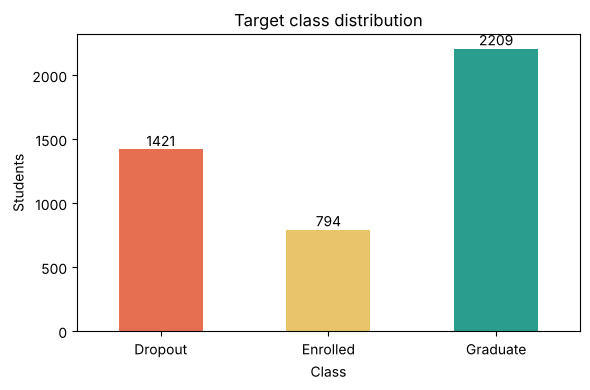

In [ ]:
print("Shape:", df.shape)
print("Total missing cells:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
counts = df["Target"].value_counts()
display(pd.DataFrame({"Count": counts,
                      "Percentage %": df["Target"].value_counts(normalize=True).mul(100).round(1)}))
fig, ax = plt.subplots(figsize=(6,4))
counts.loc[["Dropout","Enrolled","Graduate"]].plot(kind="bar",
        color=["#e76f51","#e9c46a","#2a9d8f"], ax=ax)
ax.set_title("Target class distribution"); ax.set_xlabel("Class"); ax.set_ylabel("Students")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

### 2.1 Data audit · *Lahiru*


In [ ]:
df.head()
df.info()

# summarise data type, missing counts/percentages and unique values for every column, and report exact duplicates.
summary = pd.DataFrame(index=df.columns)
summary.index.name = "Column"
summary["Data Type"] = df.dtypes.astype(str)
summary["Missing Count"] = df.isna().sum()
summary["Missing %"] = df.isna().mean().mul(100).round(2)
summary["Unique Values"] = df.nunique()
summary = summary.sort_values("Missing %", ascending=False)
display(summary)
print("Exact duplicate rows:", int(df.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,Data Type,Missing Count,Missing %,Unique Values
Column,,,,
Marital Status,int64,0,0.0,6
Application mode,int64,0,0.0,18
Application order,int64,0,0.0,8
Course,int64,0,0.0,17
Daytime/evening attendance,int64,0,0.0,2
Previous qualification,int64,0,0.0,17
Previous qualification (grade),float64,0,0.0,101
Nacionality,int64,0,0.0,21
Mother's qualification,int64,0,0.0,29


Exact duplicate rows: 0


## 3. Preprocessing & Feature Screening

The raw table becomes a matrix both models can use. Everything learned from data (encoder
levels, scaler means, PCA directions, screening scores) is learned from the training split
only and then applied unchanged to the test split, the rule Labs 04 and 05 set out.

### 3.1 Column names and column groups · *Kusal*

Two columns are renamed. The source misspells the nationality column as `Nacionality`. It also
codes `Gender` as 1 = male and 0 = female, so a column called `Gender` does not say which value
is 1. Named `Male`, it reads correctly wherever it appears.

The 36 features then fall into three groups. Nine are national registry codes stored as
integers. `Course` 9254 is not "more" than `Course` 171, so these are categories with no
ordering. Eight are already 0/1 flags, and nineteen are genuine numbers or counts.

In [ ]:
# fix the misspelt column and name the 0/1 gender flag after its value of 1
df = df.rename(columns={"Nacionality": "Nationality", "Gender": "Male"})

TARGET = "Target"
NOMINAL = ["Marital Status", "Application mode", "Course", "Previous qualification",
           "Nationality", "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Male", "Scholarship holder", "International"]
CONTINUOUS = (["Application order", "Previous qualification (grade)", "Admission grade",
               "Age at enrollment"]
              + [f"Curricular units {sem} sem ({kind})"
                 for sem in ("1st", "2nd")
                 for kind in ("credited", "enrolled", "evaluations", "approved", "grade",
                              "without evaluations")]
              + ["Unemployment rate", "Inflation rate", "GDP"])

# every feature belongs to exactly one group
assert len(NOMINAL + BINARY + CONTINUOUS) == 36
assert set(NOMINAL + BINARY + CONTINUOUS + [TARGET]) == set(df.columns)
print(f"nominal codes: {len(NOMINAL)} | binary flags: {len(BINARY)} | continuous: {len(CONTINUOUS)}")

df[NOMINAL].nunique().sort_values(ascending=False).rename("distinct codes").to_frame()

nominal codes: 9 | binary flags: 8 | continuous: 19


,distinct codes
Column,
Father's occupation,46
Father's qualification,34
Mother's occupation,32
Mother's qualification,29
Nationality,21
Application mode,18
Previous qualification,17
Course,17
Marital Status,6


### 3.2 Removing a redundant column · *Kusal*

`International` is not separate information. It is exactly "the nationality code is not 1
(Portuguese)". Keeping both adds a column and nothing else, so `International` is dropped.

In [ ]:
is_foreign = (df["Nationality"] != 1).astype(int)
print("International == (Nationality != 1) for every row:", bool((df["International"] == is_foreign).all()))

df = df.drop(columns=["International"])
BINARY.remove("International")
print("features remaining:", df.shape[1] - 1)

International == (Nationality != 1) for every row: True
features remaining: 35


### 3.3 Engineered features · *Kusal*

Each new feature is computed from a single student's row, so none can leak information between
students, and they are added before the split. The code groupings follow the code lists published
with the dataset on the UCI repository.

| feature | raw columns used | how it is built | why |
|---|---|---|---|
| `approval_rate_1st`, `approval_rate_2nd` | `Curricular units 1st sem (approved)`, `(enrolled)` and the same two for the 2nd sem | approved ÷ enrolled, per semester | 4 of 6 passed is not the same as 4 of 12 |
| `evals_per_unit_1st`, `evals_per_unit_2nd` | `Curricular units 1st sem (evaluations)`, `(enrolled)` and the same two for the 2nd sem | evaluations ÷ enrolled, per semester | repeated attempts at the same units show a student struggling |
| `unattempted_share_1st`, `unattempted_share_2nd` | `Curricular units 1st sem (without evaluations)`, `(enrolled)` and the same two for the 2nd sem | without evaluations ÷ enrolled, per semester | units left without any assessment point to a student disengaging |
| `grade_trend` | `Curricular units 1st sem (grade)`, `Curricular units 2nd sem (grade)` | 2nd sem grade − 1st sem grade | a falling and a recovering student can share an average |
| `total_approved` | `Curricular units 1st sem (approved)`, `Curricular units 2nd sem (approved)` | 1st sem approved + 2nd sem approved | overall progress in one number |
| `no_units_1st` | `Curricular units 1st sem (enrolled)` | 1 if enrolled is 0 | these students get a rate of 0, the same as a student who failed everything |
| `never_married` | `Marital Status` | 1 if the code is 1 (single, never married) | married, divorced, widowed and separated students drop out more often, so one flag replaces six codes (3.8.1) |
| `parent_edu_unknown` | `Mother's qualification`, `Father's qualification` | 1 if either parent has code 34 (unknown) | missing family information |
| `parent_occu_other_or_blank` | `Mother's occupation`, `Father's occupation` | 1 if either parent has code 90 (other situation) or 99 (blank) | unclear or missing family information |
| `parent_student` | `Mother's occupation`, `Father's occupation` | 1 if either parent has code 0 (student) | an unusual family record, with far higher dropout (3.8.1) |
| `application_group` | `Application mode` | 18 codes grouped into eight admission routes | routes with a clear meaning instead of 18 codes |
| `prev_qual_band` | `Previous qualification` | 17 codes grouped into basic, secondary, post-secondary and higher | four education bands instead of 17 codes |
| `course_field` | `Course` | 17 courses grouped into five fields of study | tested in 3.8.1 against the 17 separate courses |

These are candidates. Section 3.8.1 decides which of them, and which original columns, the models
receive. A student enrolled in no units gets a rate of 0 rather than a division by zero. There are
180 such students, and we keep them. About 43% of them drop out, compared with 32% overall, but
almost as many of them graduate, which is why they also get their own flag.

In [ ]:
def per_unit(count, enrolled):
    # no units enrolled gives 0 instead of a division by zero
    return count.div(enrolled.where(enrolled > 0)).fillna(0.0)


df["approval_rate_1st"] = per_unit(df["Curricular units 1st sem (approved)"],
                                   df["Curricular units 1st sem (enrolled)"])
df["approval_rate_2nd"] = per_unit(df["Curricular units 2nd sem (approved)"],
                                   df["Curricular units 2nd sem (enrolled)"])
df["evals_per_unit_1st"] = per_unit(df["Curricular units 1st sem (evaluations)"],
                                    df["Curricular units 1st sem (enrolled)"])
df["evals_per_unit_2nd"] = per_unit(df["Curricular units 2nd sem (evaluations)"],
                                    df["Curricular units 2nd sem (enrolled)"])
df["unattempted_share_1st"] = per_unit(df["Curricular units 1st sem (without evaluations)"],
                                       df["Curricular units 1st sem (enrolled)"])
df["unattempted_share_2nd"] = per_unit(df["Curricular units 2nd sem (without evaluations)"],
                                       df["Curricular units 2nd sem (enrolled)"])
df["grade_trend"] = df["Curricular units 2nd sem (grade)"] - df["Curricular units 1st sem (grade)"]
df["total_approved"] = (df["Curricular units 1st sem (approved)"]
                        + df["Curricular units 2nd sem (approved)"])
df["no_units_1st"] = (df["Curricular units 1st sem (enrolled)"] == 0).astype(int)
# 1 – single, 2 – married, 3 – widower, 4 – divorced, 5 – living together, 6 – legally separated
df["never_married"] = (df["Marital Status"] == 1).astype(int)
# qualification code 34 – unknown
df["parent_edu_unknown"] = ((df["Mother's qualification"] == 34)
                            | (df["Father's qualification"] == 34)).astype(int)
# occupation codes 90 – other situation, 99 – blank
df["parent_occu_other_or_blank"] = (df["Mother's occupation"].isin([90, 99])
                                    | df["Father's occupation"].isin([90, 99])).astype(int)
# occupation code 0 – student
df["parent_student"] = ((df["Mother's occupation"] == 0)
                        | (df["Father's occupation"] == 0)).astype(int)

APPLICATION_ROUTE = {
    # 1 – 1st phase, general contingent
    1: "first_phase",
    # 17 – 2nd phase, 18 – 3rd phase, general contingent
    **dict.fromkeys([17, 18], "later_phase"),
    # 2 – Ordinance No. 612/93, 5 – special contingent (Azores), 10 – Ordinance No. 854-B/99,
    # 16 – special contingent (Madeira), 26 – Ordinance No. 533-A/99 b2 (different plan),
    # 27 – Ordinance No. 533-A/99 b3 (other institution)
    **dict.fromkeys([2, 5, 10, 16, 26, 27], "special"),
    # 39 – over 23 years old
    39: "over_23",
    # 42 – transfer, 43 – change of course, 51 – change of institution/course,
    # 57 – change of institution/course (international)
    **dict.fromkeys([42, 43, 51, 57], "transfer"),
    # 7 – holders of other higher courses
    7: "higher_course_holder",
    # 44 – technological specialization diploma holders, 53 – short cycle diploma holders
    **dict.fromkeys([44, 53], "diploma_holder"),
    # 15 – international student (bachelor)
    15: "international",
}
QUALIFICATION_BAND = {
    # 9 – 12th year not completed, 10 – 11th year not completed, 11 – 7th year (old),
    # 12 – other 11th year, 13 – 2nd year complementary high school, 14 – 10th year,
    # 15 – 10th year not completed, 19 – basic education 3rd cycle,
    # 25 – complementary high school not concluded, 26 – 7th year,
    # 27 – 2nd cycle of the general high school course, 29 – 9th year not completed,
    # 30 – 8th year, 35 – can't read or write, 36 – can read without a 4th year,
    # 37 – basic education 1st cycle, 38 – basic education 2nd cycle
    **dict.fromkeys([9, 10, 11, 12, 13, 14, 15, 19, 25, 26, 27, 29, 30, 35, 36, 37, 38], "basic"),
    # 1 – secondary education (12th year), 18 – general commerce course,
    # 20 – complementary high school course, 22 – technical-professional course,
    # 31 – general course of administration and commerce,
    # 33 – supplementary accounting and administration
    **dict.fromkeys([1, 18, 20, 22, 31, 33], "secondary"),
    # 6 – frequency of higher education, 39 – technological specialization course,
    # 42 – professional higher technical course
    **dict.fromkeys([6, 39, 42], "post_secondary"),
    # 2 – bachelor's degree, 3 – degree, 4 – master's, 5 – doctorate, 40 – degree (1st cycle),
    # 41 – specialized higher studies, 43 – master (2nd cycle), 44 – doctorate (3rd cycle)
    **dict.fromkeys([2, 3, 4, 5, 40, 41, 43, 44], "higher"),
    # 34 – unknown
    34: "unknown",
}
COURSE_FIELD = {
    # 9500 – Nursing, 9085 – Veterinary Nursing, 9556 – Oral Hygiene
    **dict.fromkeys([9500, 9085, 9556], "health"),
    # 9147 – Management, 9991 – Management (evening), 9670 – Advertising and Marketing
    # Management, 9254 – Tourism
    **dict.fromkeys([9147, 9991, 9670, 9254], "management"),
    # 8014 – Social Service (evening), 9238 – Social Service, 9853 – Basic Education,
    # 9773 – Journalism and Communication
    **dict.fromkeys([8014, 9238, 9853, 9773], "social_education"),
    # 171 – Animation and Multimedia Design, 9070 – Communication Design,
    # 9119 – Informatics Engineering, 33 – Biofuel Production Technologies
    **dict.fromkeys([171, 9070, 9119, 33], "design_technology"),
    # 9003 – Agronomy, 9130 – Equinculture
    **dict.fromkeys([9003, 9130], "agriculture"),
}
df["application_group"] = df["Application mode"].map(APPLICATION_ROUTE)
df["prev_qual_band"] = df["Previous qualification"].map(QUALIFICATION_BAND)
df["course_field"] = df["Course"].map(COURSE_FIELD)
assert df[["application_group", "prev_qual_band", "course_field"]].notna().all().all()

ENGINEERED = ["approval_rate_1st", "approval_rate_2nd", "evals_per_unit_1st", "evals_per_unit_2nd",
              "unattempted_share_1st", "unattempted_share_2nd", "grade_trend", "total_approved"]
ENGINEERED_FLAGS = ["no_units_1st", "never_married", "parent_edu_unknown",
                    "parent_occu_other_or_blank", "parent_student"]
CONTINUOUS_ALL = CONTINUOUS + ENGINEERED
BINARY = BINARY + ENGINEERED_FLAGS

print("students enrolled in no units, 1st semester:", int(df["no_units_1st"].sum()))
print("\nmean of each engineered number by outcome:")
display(df.groupby(TARGET)[ENGINEERED].mean().round(3))
print("share of students with each new flag, % by outcome:")
df.groupby(TARGET)[ENGINEERED_FLAGS].mean().mul(100).round(1)

students enrolled in no units, 1st semester: 180

mean of each engineered number by outcome:


Column,approval_rate_1st,approval_rate_2nd,evals_per_unit_1st,evals_per_unit_2nd,unattempted_share_1st,unattempted_share_2nd,grade_trend,total_approved
Target,,,,,,,,
Dropout,0.384,0.293,1.272,1.186,0.034,0.041,-1.357,4.492
Enrolled,0.688,0.649,1.540,1.559,0.029,0.031,-0.008,8.377
Graduate,0.903,0.900,1.212,1.202,0.011,0.012,0.054,12.409


share of students with each new flag, % by outcome:


Column,no_units_1st,never_married,parent_edu_unknown,parent_occu_other_or_blank,parent_student
Target,,,,,
Dropout,5.4,83.3,7.2,5.5,7.9
Enrolled,3.5,90.7,0.4,0.3,0.4
Graduate,3.4,91.2,1.6,1.3,2.5


### 3.4 Train/test split · *Kusal*

One split is made once and reused by both models, with 80% for training and 20% held back
for testing, using `random_state=42` (Lab 03). For classification the split is stratified, so both
halves keep the original class proportions (Lab 05). This matters because `Enrolled` is only
17.9% of the data. The test set is not used again until section 6. Model selection uses
5-fold stratified cross-validation inside the training set.

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert len(X_train) == 3539 and len(X_test) == 885
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

pd.DataFrame({
    "train %": y_train.value_counts(normalize=True).mul(100).round(2),
    "test %": y_test.value_counts(normalize=True).mul(100).round(2),
})

Training samples: 3539
Testing samples : 885


,train %,test %
Target,,
Graduate,49.93,49.94
Dropout,32.13,32.09
Enrolled,17.94,17.97


### 3.4.1 Checking for outliers · *Kusal*

Using the IQR rule from Lab 02, a value is flagged as a possible outlier when it lies more than
1.5 × IQR below the first quartile or above the third. A flag is a reason to look at those rows,
not to delete them. The check runs on the training rows for age and admission grade.

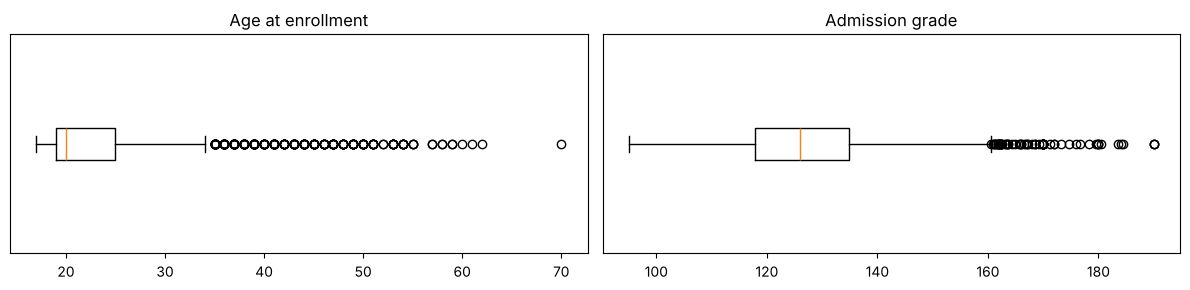

dropout rate, all training students: 32.1%
flagged ages admitted through the over-23 route: 69%


,Q1,Q3,IQR,lower fence,upper fence,flagged,dropout % flagged
feature,,,,,,,
Age at enrollment,19.0,25.0,6.0,10.00,34.00,358,53.63
Admission grade,117.8,134.9,17.1,92.15,160.55,68,33.82


In [ ]:
outlier_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, column in zip(axes, ["Age at enrollment", "Admission grade"]):
    values = X_train[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_rows.append({"feature": column, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "lower fence": q1 - 1.5 * iqr, "upper fence": q3 + 1.5 * iqr,
                         "flagged": int(flagged.sum()),
                         "dropout % flagged": y_train[flagged].eq("Dropout").mean() * 100})
    ax.boxplot(values, vert=False)
    ax.set(title=column, yticks=[])
plt.tight_layout()
plt.show()

old = X_train["Age at enrollment"] > outlier_rows[0]["upper fence"]
print(f"dropout rate, all training students: {y_train.eq('Dropout').mean():.1%}")
print(f"flagged ages admitted through the over-23 route: {X_train.loc[old, 'Application mode'].eq(39).mean():.0%}")
pd.DataFrame(outlier_rows).set_index("feature").round(2)

Age has an upper fence of 34 years, and 358 training students are above it. These are real mature
students, and 69% of them were admitted through the over-23 route. Their dropout rate is 53.6%
against 32.1% overall, so the long tail carries information about the outcome rather than errors.
Admission grade flags only 68 students, whose dropout rate is close to everyone else's. No rows are
removed. The UCI page also states that the authors already handled anomalies and outliers before
publishing the data. The long age tail is instead one reason the continuous columns are
standardised rather than min–max scaled (3.6).

### 3.5 Encoding the registry codes · *Kusal*

The nine registry-code columns store categories as numbers. Course 9500 is Nursing and course
33 is Biofuel Production Technologies, but 9500 is not "more" than 33. If these numbers were
passed in as they are, Linear Regression would treat them as amounts and give a higher code a
bigger effect. The Random Forest would split on ranges such as "course above 9000", which group
courses that have nothing in common. One-hot encoding avoids this by giving each code its own
0/1 column, so every category is learned separately and no false order is created.

Keeping every level would create a column for codes that only a handful of students have,
which gives a model nothing to learn from.
`OneHotEncoder(min_frequency=0.01)` folds every level below 1% of the training rows into one
`infrequent` column per feature, and `handle_unknown="infrequent_if_exist"` sends a code never
seen in training into that same column instead of raising an error.

The table below covers all nine code columns at the candidate stage. After 3.8.1 only three code
columns remain (`Course`, `application_group` and `prev_qual_band`), and they encode into 29
columns.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                        sparse_output=False)
encoder.fit(X_train[NOMINAL])

levels = pd.DataFrame({
    "levels": [len(c) for c in encoder.categories_],
    "folded into infrequent": [0 if f is None else len(f) for f in encoder.infrequent_categories_],
}, index=NOMINAL)
levels["columns after encoding"] = (levels["levels"] - levels["folded into infrequent"]
                                    + (levels["folded into infrequent"] > 0).astype(int))

print("columns from the nine nominal features:", len(encoder.get_feature_names_out()),
      "instead of", int(levels["levels"].sum()))
levels.sort_values("levels", ascending=False)

columns from the nine nominal features: 79 instead of 209


,levels,folded into infrequent,columns after encoding
Father's occupation,41,29,13
Father's qualification,32,25,8
Mother's occupation,31,21,11
Mother's qualification,28,20,9
Nationality,19,18,2
Application mode,18,9,10
Previous qualification,17,13,5
Course,17,1,17
Marital Status,6,3,4


### 3.6 Scaling with training statistics only · *Kusal*

`StandardScaler` centres each continuous column and divides by its standard deviation. This
matters for a gradient-based fit. On raw values, a column like age (17 to 70) and one like the
approval rate (0 to 1) are on such different scales that the same learning rate cannot suit both,
and L2 regularisation would penalise them unequally. Linear Regression needs it. Random Forest
splits one feature at a time and does not, but it uses the same scaled matrix so the two models
see identical inputs.

The alternative is **min–max normalisation**, which linearly rescales each column into a fixed
0–1 range. We chose standardisation for two reasons. Min–max is pulled toward the extremes by the
outliers this data carries (age reaches 70, and several curricular-unit counts have long right
tails), so a few students would compress everyone else into a narrow band. The gradient-descent
fit with its L2 penalty (Section 4.5) also assumes roughly zero-mean, unit-variance inputs rather
than a bounded range. Min–max keeps the outliers' pull intact and leaves each feature on a
different spread, so standardisation is the better match here.

The mean and standard deviation are learned from the training rows only and reused for the
test rows (Labs 04 and 05). The table shows the result. The training columns come out at
exactly mean 0 and standard deviation 1, and the test columns only approximately, because they
were scaled with statistics they did not contribute to.

In [ ]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train[CONTINUOUS_ALL])
test_scaled = scaler.transform(X_test[CONTINUOUS_ALL])

pd.DataFrame({
    "train mean": train_scaled.mean(axis=0),
    "train std": train_scaled.std(axis=0),
    "test mean": test_scaled.mean(axis=0),
    "test std": test_scaled.std(axis=0),
}, index=CONTINUOUS_ALL).round(3).head(8)

,train mean,train std,test mean,test std
Application order,-0.0,1.0,0.003,1.025
Previous qualification (grade),0.0,1.0,-0.027,0.995
Admission grade,-0.0,1.0,0.035,0.983
Age at enrollment,0.0,1.0,0.010,0.989
Curricular units 1st sem (credited),-0.0,1.0,-0.015,0.959
Curricular units 1st sem (enrolled),0.0,1.0,0.011,0.971
Curricular units 1st sem (evaluations),-0.0,1.0,0.009,0.990
Curricular units 1st sem (approved),0.0,1.0,0.008,0.998


### 3.7 One pipeline, so every fold is fitted separately · *Kusal*

A `ColumnTransformer` sends each group of columns to its own step (one-hot for the codes,
unchanged for the flags, scaling for the numbers) and a `Pipeline` chains it to the model.
Passed to cross-validation, the whole chain is re-fitted on each training fold, so the
validation fold never influences the encoder levels or the scaler statistics.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif


def build_preprocessor(continuous=None, pca_components=None):
    """One-hot for the codes, flags unchanged, scaling (and optional PCA) for the numbers."""
    continuous = CONTINUOUS_ALL if continuous is None else continuous
    numeric = [("scale", StandardScaler())]
    if pca_components:
        numeric.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_STATE)))
    return ColumnTransformer([
        ("nominal", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                  sparse_output=False), NOMINAL),
        ("binary", "passthrough", BINARY),
        ("continuous", Pipeline(numeric), continuous),
    ], remainder="drop", verbose_feature_names_out=False)


prep = build_preprocessor().fit(X_train, y_train)
feature_names = prep.get_feature_names_out()
n_nominal = len(prep.named_transformers_["nominal"].get_feature_names_out())
print(f"features after preprocessing: {len(feature_names)} "
      f"({n_nominal} encoded + {len(BINARY)} binary + {len(CONTINUOUS_ALL)} continuous)")


features after preprocessing: 118 (79 encoded + 12 binary + 27 continuous)


### 3.8 Feature screening · *Kusal*

The heatmap shows which number columns move together, and 3.8.1 uses it to drop repeated columns.
The ANOVA F-test and mutual information then rank every feature by its link to the outcome. ANOVA
looks for different averages between outcomes, and mutual information also catches links that are
not a straight line.


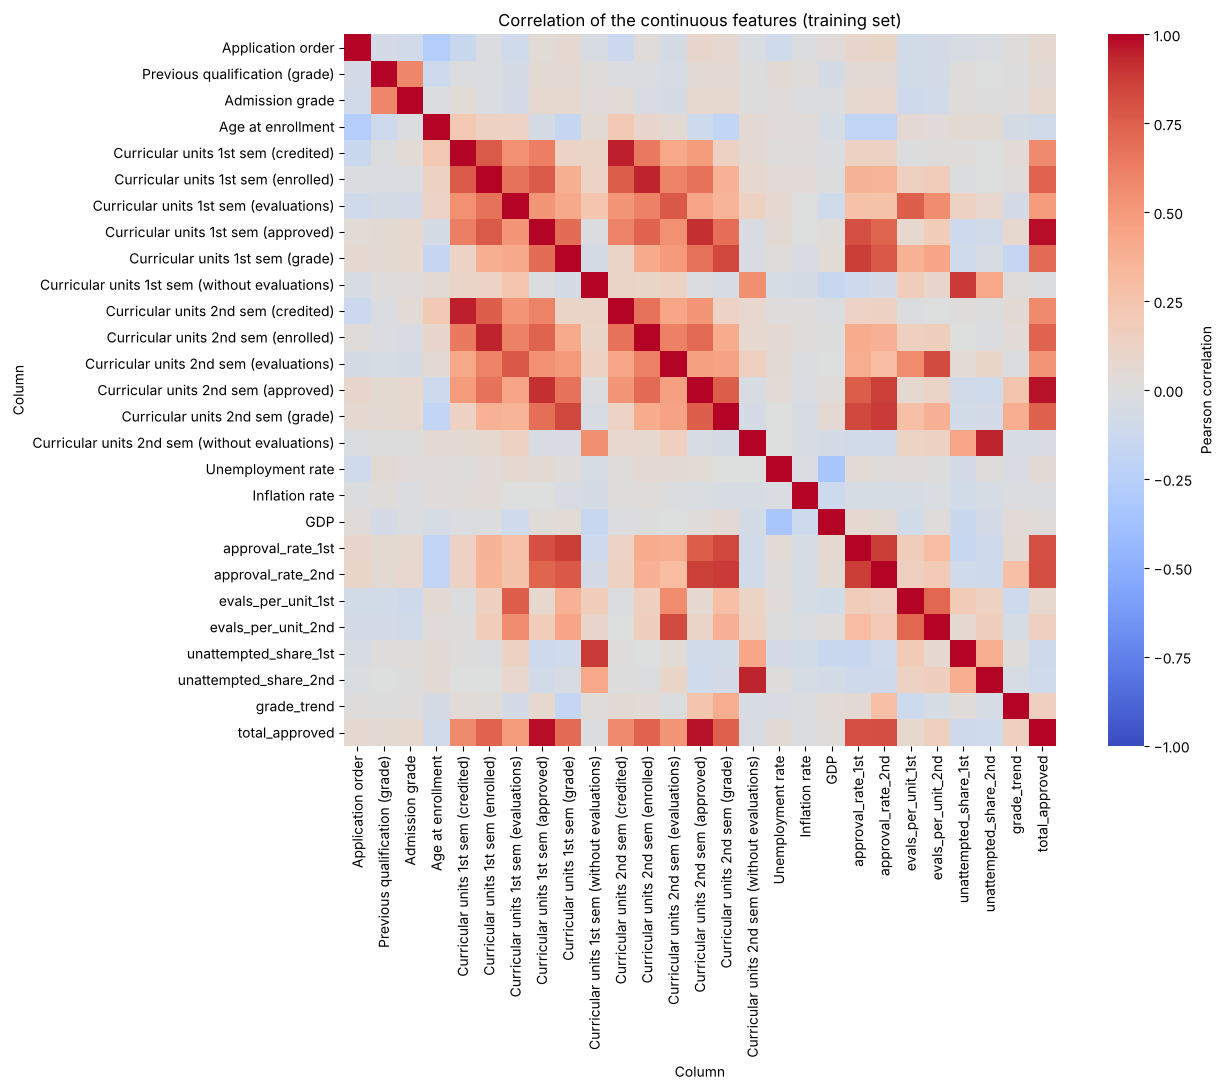

In [ ]:
import seaborn as sns

corr = X_train[CONTINUOUS_ALL].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation of the continuous features (training set)")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.feature_selection import mutual_info_classif

M_train = prep.transform(X_train)
f_scores, _ = f_classif(M_train, y_train)
mi_scores = mutual_info_classif(M_train, y_train, random_state=RANDOM_STATE)

screening = pd.DataFrame({"anova_f": f_scores.round(2), "mutual_info": mi_scores.round(4)},
                         index=feature_names)
screening["anova_rank"] = screening["anova_f"].rank(ascending=False).astype(int)
screening["mi_rank"] = screening["mutual_info"].rank(ascending=False).astype(int)
screening["mean_rank"] = (screening[["anova_rank", "mi_rank"]].mean(axis=1)).round(1)

print("top 10 features by average rank:")
screening.sort_values("mean_rank").head(10)


top 10 features by average rank:


,anova_f,mutual_info,anova_rank,mi_rank,mean_rank
approval_rate_2nd,1705.34,0.3485,1,1,1.0
Curricular units 2nd sem (approved),1092.91,0.3102,3,3,3.0
approval_rate_1st,1135.22,0.2763,2,4,3.0
total_approved,910.34,0.3162,5,2,3.5
Curricular units 2nd sem (grade),911.94,0.2382,4,5,4.5
Curricular units 1st sem (approved),660.29,0.2370,6,6,6.0
Curricular units 1st sem (grade),573.05,0.1846,7,7,7.0
Tuition fees up to date,406.06,0.0828,8,13,10.5
evals_per_unit_2nd,103.13,0.1301,13,8,10.5
grade_trend,96.03,0.1113,16,9,12.5


### 3.8.1 Choosing the final features · *Kusal*

Every candidate column has been kept up to this point, so the screening above could judge them all.
This step decides which ones the models receive. Four rules guide it.

1. **Workload counts become rates.** Counts that depend on how many units a student took are
   replaced by the per-unit rates from 3.3.
2. **Redundant columns go (Lab 02).** When a column repeats another one (r above 0.9) or is
   computed from columns that stay, one copy is enough. For a 1st/2nd-semester pair the
   1st-semester column stays, because it is available a semester earlier.
3. **Columns with no link to the outcome go.** A flag or number is dropped when the ANOVA F-test
   gives a p-value of 0.05 or more.
4. **Codes are grouped only when grouping keeps the signal.** The grouped version must keep most of
   the link to the outcome, measured with Cramér's V (0 means no link, 1 a perfect one).

| candidate | decision | reason |
|---|---|---|
| 1st and 2nd sem evaluations | replaced by `evals_per_unit` | rule 1 |
| 1st and 2nd sem without evaluations | replaced by `unattempted_share` | rule 1 |
| 1st and 2nd sem approved | dropped | both repeat `total_approved` (r = 0.98) |
| 2nd sem enrolled | dropped | repeats 1st sem enrolled (r = 0.94) |
| 2nd sem credited | dropped | repeats 1st sem credited (r = 0.95) |
| `grade_trend` | dropped | it is exactly 2nd sem grade minus 1st sem grade |
| Inflation rate | dropped | no link to the outcome (p = 0.16) |
| Educational special needs | dropped | no link to the outcome (p = 0.79) |
| Nationality | dropped | being Portuguese or not has no link to the outcome (p = 0.24) |
| Marital Status | replaced by `never_married` | never-married students drop out 30% of the time, against 45% for divorced and 49% for married students, so the other codes are not counted as single. Widowed and separated students are too few to judge |
| Mother's and father's qualification and occupation | replaced by three flags | the education level barely changes dropout (28% to 36% in every band with more than 20 students), but when a parent's details are missing dropout rises to about 70% |
| Application mode | grouped into `application_group` | eight routes keep most of the link (V from 0.25 to 0.24). They keep 1st-phase entrants (20% dropout) apart from later phases (31%), and holders of other higher courses (62%) apart from diploma holders (26%) |
| Previous qualification | grouped into `prev_qual_band` | four bands keep most of the link (V from 0.16 to 0.15) |
| Course | kept as 17 courses | five fields lose about a third of the link (V from 0.26 to 0.17) |

The cells below print the numbers behind this table.

In [ ]:
from scipy.stats import chi2_contingency

# rule 2: correlation between columns that repeat each other
corr = X_train.corr(numeric_only=True)
print("Correlation between repeated columns")
print("  1st sem approved vs total_approved:",
      round(corr.loc["Curricular units 1st sem (approved)", "total_approved"], 2))
print("  2nd sem approved vs total_approved:",
      round(corr.loc["Curricular units 2nd sem (approved)", "total_approved"], 2))
print("  1st sem vs 2nd sem enrolled:",
      round(corr.loc["Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"], 2))
print("  1st sem vs 2nd sem credited:",
      round(corr.loc["Curricular units 1st sem (credited)", "Curricular units 2nd sem (credited)"], 2))

# rule 3: ANOVA p-values for the columns with no link to the outcome
portuguese = (X_train["Nationality"] == 1).astype(int).to_frame("Portuguese")
print("\nANOVA p-values (0.05 or more means no link to the outcome)")
print("  Inflation rate:", round(f_classif(X_train[["Inflation rate"]], y_train)[1][0], 2))
print("  Educational special needs:",
      round(f_classif(X_train[["Educational special needs"]], y_train)[1][0], 2))
print("  Portuguese or not:", round(f_classif(portuguese, y_train)[1][0], 2))


Correlation between repeated columns
  1st sem approved vs total_approved: 0.98
  2nd sem approved vs total_approved: 0.98
  1st sem vs 2nd sem enrolled: 0.94
  1st sem vs 2nd sem credited: 0.95

ANOVA p-values (0.05 or more means no link to the outcome)
  Inflation rate: 0.16
  Educational special needs: 0.79
  Portuguese or not: 0.24


In [ ]:
# a dropout column (100 = dropped out, 0 = did not) so each group's mean is its dropout %
train = X_train.copy()
train["dropout"] = (y_train == "Dropout").astype(int) * 100

print("Dropout % by marital status (1 single, 2 married, 3 widower, 4 divorced, 5 together, 6 separated)")
display(train.groupby("Marital Status")["dropout"].agg(students="count", dropout_percent="mean").round(1))

print("Dropout % by admission route")
display(train.groupby("application_group")["dropout"].agg(students="count", dropout_percent="mean").round(1))

train["mother_education"] = train["Mother's qualification"].map(QUALIFICATION_BAND)
train["father_education"] = train["Father's qualification"].map(QUALIFICATION_BAND)
print("Dropout % by parent's education band")
display(pd.DataFrame({
    "mother": train.groupby("mother_education")["dropout"].mean(),
    "father": train.groupby("father_education")["dropout"].mean(),
}).round(1))

print("Dropout % without (0) and with (1) each parent flag")
pd.DataFrame({
    "parent_edu_unknown": train.groupby("parent_edu_unknown")["dropout"].mean(),
    "parent_occu_other_or_blank": train.groupby("parent_occu_other_or_blank")["dropout"].mean(),
    "parent_student": train.groupby("parent_student")["dropout"].mean(),
}).round(1)


Dropout % by marital status (1 single, 2 married, 3 widower, 4 divorced, 5 together, 6 separated)


,students,dropout_percent
Marital Status,,
1,3144,30.2
2,296,48.6
3,3,33.3
4,73,45.2
5,19,42.1
6,4,75.0


Dropout % by admission route


,students,dropout_percent
application_group,,
diploma_holder,207,25.6
first_phase,1364,19.6
higher_course_holder,109,62.4
international,24,8.3
later_phase,799,30.9
over_23,621,56.5
special,61,19.7
transfer,354,38.7


Dropout % by parent's education band


,mother,father
basic,31.9,30.4
higher,30.1,35.6
post_secondary,50.0,42.1
secondary,28.2,30.7
unknown,74.1,73.1


Dropout % without (0) and with (1) each parent flag


,parent_edu_unknown,parent_occu_other_or_blank,parent_student
0,30.7,31.2,30.7
1,72.6,69.8,67.4


In [ ]:
# rule 4: Cramér's V (0 = no link, 1 = perfect link) for raw codes and their grouped version
def cramers_v(column):
    table = pd.crosstab(X_train[column], y_train)
    chi2_value = chi2_contingency(table)[0]
    return round(np.sqrt(chi2_value / (len(X_train) * (min(table.shape) - 1))), 3)


pd.DataFrame({
    "raw codes": [cramers_v("Application mode"), cramers_v("Previous qualification"),
                  cramers_v("Course")],
    "grouped": [cramers_v("application_group"), cramers_v("prev_qual_band"),
                cramers_v("course_field")],
}, index=["Application mode", "Previous qualification", "Course"])


,raw codes,grouped
Application mode,0.246,0.235
Previous qualification,0.162,0.148
Course,0.255,0.165


The cell below fixes the final lists and checks rules 2 and 3 on them. From here on `NOMINAL`,
`BINARY` and `CONTINUOUS_ALL` hold only the final features, so every pipeline built later uses them.

In [ ]:
candidate_width = len(feature_names)

NOMINAL = ["Course", "application_group", "prev_qual_band"]
BINARY = ["Daytime/evening attendance", "Displaced", "Debtor", "Tuition fees up to date", "Male",
          "Scholarship holder", "never_married", "no_units_1st", "parent_edu_unknown",
          "parent_occu_other_or_blank", "parent_student"]
CONTINUOUS_ALL = ["Application order", "Previous qualification (grade)", "Admission grade",
                  "Age at enrollment", "Curricular units 1st sem (credited)",
                  "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (grade)",
                  "Curricular units 2nd sem (grade)", "approval_rate_1st", "approval_rate_2nd",
                  "total_approved", "evals_per_unit_1st", "evals_per_unit_2nd",
                  "unattempted_share_1st", "unattempted_share_2nd", "Unemployment rate", "GDP"]

kept_p = f_classif(X_train[BINARY + CONTINUOUS_ALL], y_train)[1]
kept_r = X_train[CONTINUOUS_ALL].corr().abs().to_numpy()[np.triu_indices(len(CONTINUOUS_ALL), k=1)]
assert (kept_p < 0.05).all(), "every kept flag and number is associated with the outcome"
assert kept_r.max() < 0.9, "no two kept numbers move almost exactly together"

prep = build_preprocessor().fit(X_train, y_train)
feature_names = prep.get_feature_names_out()
n_nominal = len(prep.named_transformers_["nominal"].get_feature_names_out())
print(f"final features after preprocessing: {len(feature_names)} "
      f"({n_nominal} encoded + {len(BINARY)} binary + {len(CONTINUOUS_ALL)} continuous), "
      f"down from {candidate_width} candidate columns")

final features after preprocessing: 57 (29 encoded + 11 binary + 17 continuous), down from 118 candidate columns


### 3.9 Dimensionality reduction with PCA · *Kusal*

PCA replaces correlated columns with uncorrelated combinations ordered by how much variance
each explains. It is applied to the final continuous columns from 3.8.1, scaled, and to nothing
else, because rotating one-hot columns would mix unrelated categories into components nobody
could interpret. The number of components is chosen here from the training rows. Inside the
models, PCA sits in the pipeline and is re-fitted on every training fold.

components for 80% of the variance: 7
components for 90% of the variance: 10
components for 95% of the variance: 12
components for 99% of the variance: 15
components for 99.9% of the variance: 17
components for 99.99% of the variance: 17

chosen: 12 components of 17 continuous columns


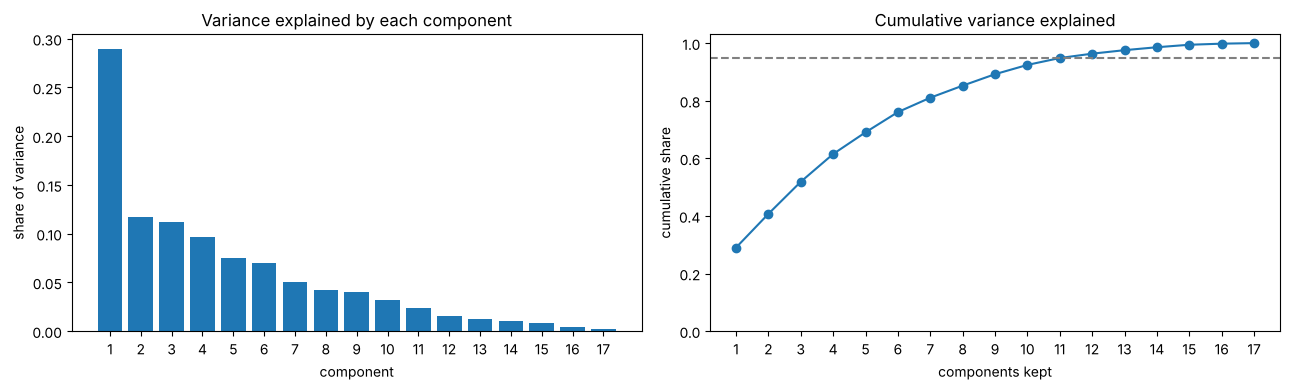

strongest loadings on the first component:


approval_rate_1st                      0.411
total_approved                         0.409
Curricular units 2nd sem (grade)       0.409
Curricular units 1st sem (grade)       0.404
approval_rate_2nd                      0.402
Curricular units 1st sem (enrolled)    0.273
dtype: float64

In [ ]:
final_scaled = StandardScaler().fit_transform(X_train[CONTINUOUS_ALL])
pca_full = PCA(random_state=RANDOM_STATE).fit(final_scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()

for share in (0.80, 0.90, 0.95, 0.99, 0.999, 0.9999):
    print(f"components for {share * 100:g}% of the variance: {int((cumulative < share).sum() + 1)}")
PCA_COMPONENTS = int((cumulative < 0.95).sum() + 1)
print(f"\nchosen: {PCA_COMPONENTS} components of {len(CONTINUOUS_ALL)} continuous columns")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
components = np.arange(1, len(cumulative) + 1)
axes[0].bar(components, pca_full.explained_variance_ratio_)
axes[0].set(title="Variance explained by each component", xlabel="component",
            ylabel="share of variance")
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.95, linestyle="--", color="grey")
axes[1].set(title="Cumulative variance explained", xlabel="components kept",
            ylabel="cumulative share", ylim=(0, 1.03))
axes[0].set_xticks(components)
axes[1].set_xticks(components)
plt.tight_layout()
plt.show()

loadings = pd.Series(pca_full.components_[0], index=CONTINUOUS_ALL)
print("strongest loadings on the first component:")
loadings.abs().sort_values(ascending=False).head(6).round(3)

The curve flattens towards the end. The first 12 components already hold 96% of the variance and
15 hold 99%, while the last two add less than 1% together. There are only 17 components, one for
each number column, so all 17 always reach 100%, and even 99.9% needs every one of them. Keeping
12 drops five components that together hold about 4% of the variance.


### 3.10 The four feature variants the models use · *Kusal*

Each variant uses the same models and folds, so the effect of the feature set can be separated
from the effect of the algorithm. The Random Forest is tested on all four (5.5), and Linear
Regression on `all` and `first_sem` (4.8).

| variant | what it is | question it answers |
|---|---|---|
| `all` | every final feature from 3.8.1, encoded and scaled | the baseline set |
| `reduced` | the 40 strongest of the 57 final features by ANOVA F, which drops the 17 weakest | does keeping only the strongest features help? |
| `pca` | continuous block replaced by its principal components | dimensionality reduction by extraction |
| `first_sem` | second-semester columns withheld | how early can a warning be issued? |

`first_sem` is about when data becomes available, not leakage. Second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in.

In [ ]:
FIRST_SEM = [c for c in CONTINUOUS_ALL if "2nd" not in c and c != "total_approved"]


def build_pipeline(model, variant="all", k=40):
    """The preprocessing plus a model, for one of the four feature variants."""
    if variant == "first_sem":
        prep_step = build_preprocessor(continuous=FIRST_SEM)
    elif variant == "pca":
        prep_step = build_preprocessor(pca_components=PCA_COMPONENTS)
    else:
        prep_step = build_preprocessor()
    steps = [("prep", prep_step)]
    if variant == "reduced":
        steps.append(("select", SelectKBest(f_classif, k=k)))
    return Pipeline(steps + [("model", model)])


from sklearn.dummy import DummyClassifier

widths = {variant: build_pipeline(DummyClassifier(), variant).fit(X_train, y_train)[:-1]
          .transform(X_train).shape[1]
          for variant in ("all", "reduced", "pca", "first_sem")}
pd.Series(widths, name="features").to_frame()

,features
all,57
reduced,40
pca,52
first_sem,52


### 3.11 Baseline and shared scoring · *Kusal*

A model that always predicts `Graduate` reaches about 50% accuracy but only 0.22 macro-F1, so the
models are judged on macro-F1. Both models are scored by the same function on out-of-fold
predictions, so their results can be compared directly in section 6.


In [ ]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.model_selection import cross_val_predict

CLASSES = ["Dropout", "Enrolled", "Graduate"]

baseline = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                          cv=cv, scoring=["accuracy", "f1_macro"])
print(f"always-Graduate baseline: accuracy {baseline['test_accuracy'].mean():.3f} | "
      f"macro-F1 {baseline['test_f1_macro'].mean():.3f}")


def cv_scores(pipeline, X, y, name, variant, binary=False):
    """Cross-validated scores from out-of-fold predictions, as one row of a results table."""
    proba = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba")
    if binary:
        predicted = (proba[:, 1] >= 0.5).astype(int)
    else:
        predicted = np.unique(y)[proba.argmax(axis=1)]

    row = {
        "model": name,
        "variant": variant,
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "f1_macro": f1_score(y, predicted, average="macro"),
        "mcc": matthews_corrcoef(y, predicted),
    }
    if binary:
        row["roc_auc"] = roc_auc_score(y, proba[:, 1])
        row["pr_auc"] = average_precision_score(y, proba[:, 1])
        row["recall_dropout"] = recall_score(y, predicted)
    else:
        row["roc_auc"] = roc_auc_score(y, proba, multi_class="ovr", labels=np.unique(y))
        per_class = recall_score(y, predicted, average=None, labels=CLASSES)
        row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, per_class)})
    return row

always-Graduate baseline: accuracy 0.499 | macro-F1 0.222


## 4. Model 1 — Linear Regression · *Lahiru*

Linear regression is a **linear, model-based** supervised method: it learns weights θ for a straight-line combination of
the features. Section 4.1 gives its background and justifies the choice; the rest builds the model, shows **how its
weights are learned** (cost, gradient descent, learning rate α, normal equation), **selects a feature set**, and turns
linear regression into a **classifier for our three outcomes in three ways**, all *linear in the parameters*:

| Route | Idea | Stays linear in θ? | Handles our 3 classes by |
|---|---|---|---|
| **A — ordinal score** | predict one continuous *success score*, then round to the nearest class | yes | assuming the classes are ordered & equally spaced |
| **B — multivariate (indicator)** | regress **three outputs at once** (one indicator column per class), take the largest | yes | one regression plane per class, then `argmax` |
| **C — polynomial** | add squared/interaction terms of the selected features, still fit by least squares | yes (nonlinear in *x*, linear in *θ*) | bending the decision surface |

### 4.1 Introduction, background & justification of the algorithm · *Lahiru*

**What linear regression is.** Linear regression is one of the oldest and most fundamental supervised-learning
algorithms, dating to the least-squares method of Gauss and Legendre (early 1800s). It is a **parametric, model-based**
method: it assumes the target is approximately a *linear combination* of the input features and learns a weight vector θ
that minimises the squared error between predictions and truth. The optimum can be found in closed form (the **normal
equation**) or iteratively by **gradient descent** — both shown in 4.9.

**Assumptions (and where we check them).** Linear regression works best when (i) the relationship between features and
target is roughly **linear**, (ii) errors are **independent** and (iii) of roughly **constant variance**
(homoscedasticity), and (iv) features are not severely **collinear**. We inspect linearity and error behaviour in the
residual diagnostics (4.8), and we treat the near-collinear curricular-unit features with **Ridge** regularization
(4.10). Standardising the continuous features (the pipeline from Section 3) keeps the weights on a comparable scale.

**Why we chose it as Model 1 (justification).**

- **A meaningful contrast for the assignment.** The brief requires **two distinct supervised algorithms** compared on the
  same data. Pairing an interpretable **linear/parametric** model (Model 1) against Kusal's **non-linear ensemble**,
  Random Forest (Model 2), is a clean, textbook contrast — linear vs non-linear decision surface, high-bias/low-variance
  vs low-bias/higher-variance, and transparent coefficients vs black-box feature importances.
- **A strong, transparent baseline.** Linear regression is fast and its **signed coefficients say *which* factors push a
  student toward graduating or dropping out** (4.11). It sets the bar the forest must clear: if the ensemble cannot beat a
  tuned linear baseline, its extra complexity is not justified.
- **It exercises the taught material.** The build follows **Lab 3** (baseline → fit → metrics → diagnostics →
  coefficients) and **Lab 4** (scaling, cost function, gradient descent, learning rate, normal equation, Ridge).
- **Honest adaptation to a classification target.** Our label has three categories, and plain linear regression predicts
  a *number*, not a class. Rather than force-fit it, we adapt it three principled ways that stay *linear in the
  parameters* — ordinal rounding, multivariate **indicator** regression, and **polynomial** features (4.12) — and we
  **measure** the trade-offs (including the classic middle-class *masking* effect). Stating and quantifying this
  limitation is part of the analysis, not a flaw hidden from the reader.

### 4.2 The formulated functions — how linear regression predicts and how we score it · *Lahiru*

**The model (hypothesis).** For a student with feature vector $x = (x_1,\dots,x_n)$, linear regression predicts

$$\hat{y} = h_\theta(x) = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n = \theta^\top x \quad(\text{with } x_0=1).$$

The weights $\theta$ are the only thing learned. **Polynomial regression (route C)** simply replaces $x$ with an
expanded vector $\phi(x) = (x_1,\dots,x_n,\,x_1^2,\,x_1x_2,\dots)$; because each new term still enters through its own
weight, $h_\theta(\phi(x))$ is **nonlinear in $x$ but linear in $\theta$**, so it is fit by the same least squares.
**Multivariate regression (route B)** stacks $K=3$ such models, one per class, predicting a $K$-vector at once:
$\hat{Y} = X\hat{B}$.

**How the weights are found (the cost).** Least squares chooses $\theta$ to minimise the mean squared error

$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big)^2 .$$

Two equivalent routes to the minimum (both in 4.9): the closed-form **normal equation**
$\theta = (X^\top X)^{-1} X^\top y$, and **gradient descent**, which steps downhill

$$\theta_j \leftarrow \theta_j - \alpha\,\frac{\partial J}{\partial \theta_j}
      = \theta_j - \alpha\,\frac{1}{m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)})-y^{(i)}\big)x_j^{(i)},$$

where **$\alpha$ is the learning rate** — the step size. Too small and it crawls; too large and $J(\theta)$ diverges
(4.9 finds a good $\alpha$ empirically). Feature scaling (in our pipeline) is what lets a single $\alpha$ work for every
feature at once.

**How we score it (predict accuracy with a formula).** Regression quality uses

$$\text{RMSE}=\sqrt{\tfrac{1}{m}\textstyle\sum (y-\hat{y})^2}, \qquad
  R^2 = 1 - \frac{\sum (y-\hat{y})^2}{\sum (y-\bar{y})^2}.$$

Once a route turns the prediction into a class, we score it with the **classification** formulas from Lab 8:
$\text{accuracy}=\frac{TP+TN}{N}$, $\text{precision}=\frac{TP}{TP+FP}$, $\text{recall}=\frac{TP}{TP+FN}$,
$F_1=\frac{2PR}{P+R}$, and MCC (all four confusion-matrix cells). Because the classes are imbalanced, we lead with
**macro-F1, balanced accuracy and MCC**, not accuracy — exactly the lecture's "accuracy trap" warning.

### 4.3 Setup — imports & configuration · *Lahiru*

All of Section 4's tunable values live here once, as **named constants** (no magic numbers scattered through the code),
together with the ordinal class encoding. Changing a setting in this one cell changes it everywhere below.

In [22]:
# ============================================================================
# Section 4 — setup: imports and configuration
# Every tunable value lives here as a named constant (no magic numbers below).
# ============================================================================
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_predict
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import PolynomialFeatures

# --- target encoding: academic success is ordered  Dropout < Enrolled < Graduate ---
ORDER = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
LABELS_SORTED = np.array(["Dropout", "Enrolled", "Graduate"])   # index 0/1/2 matches ORDER

# --- configuration constants (referenced throughout Section 4) ---
SELECTED_K     = 20                              # 4.5 / 4.12  size of the filter-selected feature set
POLY_DEGREE    = 2                               # 4.12        polynomial-expansion degree (route C)
GD_ALPHA       = 0.1                             # 4.9         gradient-descent learning rate for the fit
GD_ITERATIONS  = 20_000                          # 4.9         gradient-descent steps for the fit
LEARNING_RATES = [0.001, 0.01, 0.1, 0.3, 1.5]   # 4.9         learning rates compared in the alpha sweep
LR_SWEEP_ITERS = 300                            # 4.9         iterations per rate in the alpha sweep
RIDGE_LAMBDAS  = [0.0, 0.1, 1.0, 10.0, 100.0]   # 4.10        L2 penalty strengths compared
TOP_COEF_N     = 12                             # 4.11        number of coefficients plotted
JITTER_SD      = 0.03                           # 4.8         jitter std-dev for the diagnostic scatter

print("Section 4 configured — classes:", list(ORDER),
      "| selected features:", SELECTED_K, "| polynomial degree:", POLY_DEGREE)

Section 4 configured — classes: ['Dropout', 'Enrolled', 'Graduate'] | selected features: 20 | polynomial degree: 2


### 4.4 Frame the target as an ordinal success score · *Lahiru*

**Why.** Routes A and C need a single numeric target. **How.** Map each label to its success rank and keep the mapping
so predictions can be turned back into classes. **Read the result:** the proportions are the class balance the baseline
exploits — `Enrolled` is the smallest class and sits *between* the other two, which (as 4.12 shows) is exactly why it is
the hardest class for a linear model to recover.

In [23]:
# Map each class label to its ordinal success rank; the inverse (LABELS_SORTED) turns
# a predicted score back into a class label in 4.12.
y_train_reg = y_train.map(ORDER).astype(float)          # continuous regression target

distribution = y_train_reg.value_counts().sort_index().rename("count").to_frame()
distribution.index = [f"{int(i)} = {LABELS_SORTED[int(i)]}" for i in distribution.index]
distribution["proportion"] = (distribution["count"] / distribution["count"].sum()).round(3)
print("Ordinal mapping:", ORDER)
print("Success-score distribution in the training set:")
display(distribution)
print(f"Mean success score (what the 4.6 baseline will predict for everyone): {y_train_reg.mean():.4f}")

Ordinal mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Success-score distribution in the training set:


,count,proportion
0 = Dropout,1137,0.321
1 = Enrolled,635,0.179
2 = Graduate,1767,0.499


Mean success score (what the 4.6 baseline will predict for everyone): 1.1780


### 4.5 The feature set the routes reuse · *Lahiru*

**Why.** Instead of throwing every column at every route, we select a compact, informative **feature set** once and reuse
it — fewer features means less variance and a readable polynomial expansion in 4.12 (route C). **How.** This is a
**filter** method (lecture §2): because the success score is numeric, we rank features by the **F-regression** score
(numeric feature vs numeric target), the regression analogue of the ANOVA screening used for the classifiers in §3.8.
The top-`SELECTED_K` features form the set; inside every model the same `SelectKBest` step is **re-fitted on each training
fold**, so the choice never sees the validation data. **Read the result:** expect the curricular-unit (approved / grade)
columns to top the list — the same features the correlation screening flagged.

In [24]:
# Filter feature selection: rank the preprocessed features by their linear relationship
# with the continuous success score (numeric feature vs numeric target -> F-regression).
# Reuses the preprocessor already fitted in Section 3 (`prep`) — one shared preprocessing
# definition across all sections, nothing re-fitted here.
design_matrix = prep.transform(X_train)
f_scores, p_values = f_regression(design_matrix, y_train_reg)

feature_ranking = (pd.DataFrame({"feature": feature_names,
                                 "F_regression": f_scores, "p_value": p_values})
                   .sort_values("F_regression", ascending=False).reset_index(drop=True))
feature_ranking.index += 1
feature_ranking.index.name = "rank"

SELECTED_K = min(SELECTED_K, design_matrix.shape[1])   # never exceed available features
selected_features = feature_ranking["feature"].head(SELECTED_K).tolist()
print(f"Preprocessed features available : {design_matrix.shape[1]}")
print(f"Selected feature set            : top {SELECTED_K} by F-regression")
print("(re-selected inside each CV fold via SelectKBest, so there is no leakage)\n")
display(feature_ranking.head(SELECTED_K).round({"F_regression": 1, "p_value": 4}))

Preprocessed features available : 57
Selected feature set            : top 20 by F-regression
(re-selected inside each CV fold via SelectKBest, so there is no leakage)



,feature,F_regression,p_value
rank,,,
1,approval_rate_2nd,3367.4,0.0
2,approval_rate_1st,2248.1,0.0
3,total_approved,1821.1,0.0
4,Curricular units 2nd sem (grade),1674.4,0.0
5,Curricular units 1st sem (grade),1090.8,0.0
6,Tuition fees up to date,719.8,0.0
7,Scholarship holder,333.4,0.0
8,Debtor,238.8,0.0
9,Age at enrollment,226.6,0.0


### 4.6 The baseline every model must beat · *Lahiru*

**What a baseline is, and why.** A score in isolation is meaningless — "RMSE 0.56" is only good or bad *relative to
something*. The baseline is the **zero-skill reference**: the best you can do while ignoring the features. For regression
that is `DummyRegressor(strategy="mean")`, which predicts the **mean success score for every student** (the classifier
counterpart, used in §3.11, always predicts the majority class `Graduate`). **How.** Score it with the same 5-fold CV on
the training set. **Read the result:** its $R^2$ is $\approx 0$ by construction (it explains none of the variance), and
its RMSE (≈ 0.89 score-units) is the number 4.7 must beat. If a "real" model cannot beat this, the features add nothing.

In [25]:
def reg_cv_predict(model, variant="all"):
    """Return out-of-fold success-score predictions (5-fold CV on the training set)."""
    pipeline = build_pipeline(model, variant=variant)
    return cross_val_predict(pipeline, X_train, y_train_reg, cv=cv)

baseline_oof = cross_val_predict(DummyRegressor(strategy="mean"), X_train, y_train_reg, cv=cv)
baseline_rmse = np.sqrt(mean_squared_error(y_train_reg, baseline_oof))
baseline_r2 = r2_score(y_train_reg, baseline_oof)
print(f"Mean baseline (5-fold CV):  RMSE = {baseline_rmse:.4f} | R^2 = {baseline_r2:.4f}")

Mean baseline (5-fold CV):  RMSE = 0.8882 | R^2 = -0.0000


### 4.7 Multiple linear regression with all features (Lab 3, Part D) · *Lahiru*

**Why.** This is the core model: one linear combination of all inputs predicting the success score.
**How.** `LinearRegression` runs through the shared preprocessing pipeline (one-hot for the registry codes, pass-through
for the binary flags, standardisation for the continuous/engineered numbers), **fit inside each fold** so nothing leaks.
**Read the result:** compare RMSE and R² against the 4.6 baseline — a large RMSE drop and an R² well above 0 mean the
features carry real signal about academic success.

In [26]:
lr_oof = reg_cv_predict(LinearRegression(), variant="all")
lr_mse = mean_squared_error(y_train_reg, lr_oof)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_train_reg, lr_oof)

print("Linear Regression (all features, 5-fold CV on training set)")
print(f"  MSE  : {lr_mse:.4f}")
print(f"  RMSE : {lr_rmse:.4f}")
print(f"  R^2  : {lr_r2:.4f}")
print(f"  RMSE improvement over baseline: {baseline_rmse - lr_rmse:.4f}")
display(pd.DataFrame({"RMSE": [baseline_rmse, lr_rmse], "R_squared": [baseline_r2, lr_r2]},
                     index=["Mean baseline", "Linear regression"]).round(4))

Linear Regression (all features, 5-fold CV on training set)
  MSE  : 0.3081
  RMSE : 0.5550
  R^2  : 0.6095
  RMSE improvement over baseline: 0.3331


,RMSE,R_squared
Mean baseline,0.8882,-0.0000
Linear regression,0.5550,0.6095


**Result (4.7).** Linear regression reaches **RMSE ≈ 0.56** against the baseline's **≈ 0.89**, and **R² ≈ 0.61** — it
explains about **61 % of the variance** in the ordinal success score, cutting the baseline error by roughly a third.
So a straight linear combination of the features already captures most of the systematic variation; what it *cannot*
capture is examined in the diagnostics next.

### 4.8 Diagnose the fitted model (Lab 3, Part E) · *Lahiru*

**Why.** A good RMSE does not prove the *linear form* is appropriate — the residuals do (assumption check from 4.1).
**How.** Plot actual-vs-predicted and residual-vs-predicted using the **out-of-fold** success scores (never on data the
model trained on). The true score is only 0/1/2, so points fall in three horizontal bands; small jitter is added only so
overlapping points stay visible. **Read the result:** a good fit hugs the dashed `y = x` line and leaves residuals
scattered evenly around 0. The three sloping residual bands here are the signature of forcing a continuous line onto
three ordered categories — the very thing routes B and C try to relax.

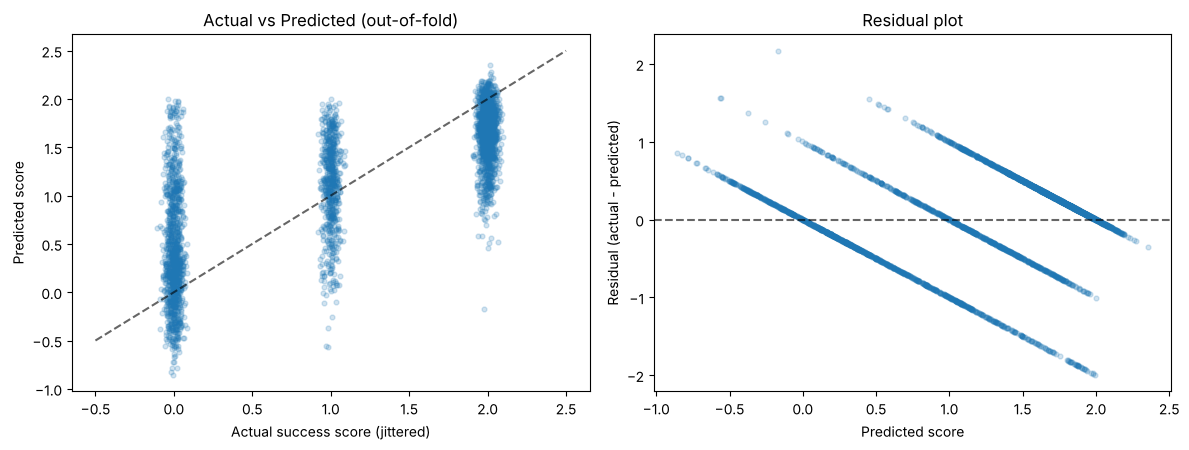

Residual mean: -0.0013  (near 0 => unbiased on average)
Residual std : 0.5550


In [27]:
rng = np.random.default_rng(RANDOM_STATE)      # seed the jitter so the plot is reproducible
residuals = y_train_reg.values - lr_oof

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(y_train_reg + rng.normal(0, JITTER_SD, len(y_train_reg)), lr_oof, alpha=0.2, s=12)
diagonal = (-0.5, 2.5)
axes[0].plot(diagonal, diagonal, "k--", alpha=0.6)
axes[0].set_xlabel("Actual success score (jittered)"); axes[0].set_ylabel("Predicted score")
axes[0].set_title("Actual vs Predicted (out-of-fold)")
axes[1].scatter(lr_oof, residuals, alpha=0.2, s=12)
axes[1].axhline(0, color="k", ls="--", alpha=0.6)
axes[1].set_xlabel("Predicted score"); axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residual plot")
plt.tight_layout(); plt.show()

print(f"Residual mean: {residuals.mean():+.4f}  (near 0 => unbiased on average)")
print(f"Residual std : {residuals.std():.4f}")

### 4.9 How the weights θ are learned, and the learning rate α (Lab 4) · *Lahiru*

**Why.** The weights are not magic: the same optimum is reachable three equivalent ways, and the **learning rate α**
controls whether gradient descent reaches it at all.
**How.** On the preprocessed **training** design matrix we run **gradient descent** (iteratively minimise `J(θ)` using the
update rule from 4.2), the **normal equation** (closed form `θ = (XᵀX)⁻¹Xᵀy`), and **scikit-learn** as a check; then we
sweep α to see how it is chosen.
**Read the result:** the normal equation and scikit-learn match to machine precision and gradient descent reaches the
same cost (the table lists the largest weights side by side). In the α sweep, a **too-small α** crawls, a **good α** drops
smoothly, and a **too-large α** makes the cost **diverge** — so we keep the largest α that still decreases `J(θ)`
monotonically.

In [28]:
def compute_cost(X, y, theta):
    """Least-squares cost  J(theta) = (1 / 2m) * sum((X @ theta - y) ** 2)."""
    m = len(y)
    error = X @ theta - y
    return float(((error.T @ error) / (2 * m)).item())

def gradient_descent(X, y, theta, alpha, iterations, stop_on_nonfinite=True):
    """Batch gradient descent on the least-squares cost; returns (theta, cost_history)."""
    m = len(y)
    theta = theta.astype(float).copy()
    history = []
    for i in range(iterations):
        gradient = (X.T @ (X @ theta - y)) / m
        theta = theta - alpha * gradient
        cost = compute_cost(X, y, theta)
        history.append(cost)
        if stop_on_nonfinite and not np.isfinite(cost):
            print(f"Stopped at iteration {i + 1}: cost became non-finite.")
            break
    return theta, np.asarray(history)

# Preprocessed TRAINING design matrix, reusing Section 3's fitted preprocessor (`prep`),
# with a leading intercept column for the by-hand solvers below.
design_feature_names = np.r_[["intercept"], feature_names]
X_design = np.c_[np.ones((len(X_train), 1)), prep.transform(X_train).astype(float)]
y_vector = y_train_reg.to_numpy(dtype=float).reshape(-1, 1)
theta_init = np.zeros((X_design.shape[1], 1))
print("Design matrix:", X_design.shape,
      "| initial cost:", round(compute_cost(X_design, y_vector, theta_init), 4))

# Three equivalent routes to the same optimum
theta_gd, cost_history = gradient_descent(X_design, y_vector, theta_init, GD_ALPHA, GD_ITERATIONS)
theta_normal = np.linalg.pinv(X_design.T @ X_design) @ X_design.T @ y_vector     # closed form
sklearn_fit = LinearRegression(fit_intercept=False).fit(X_design, y_vector.ravel())
theta_sklearn = sklearn_fit.coef_.reshape(-1, 1)

pred_gd = X_design @ theta_gd
pred_normal = X_design @ theta_normal
pred_sklearn = sklearn_fit.predict(X_design).reshape(-1, 1)

theta_table = pd.DataFrame({"feature": design_feature_names,
                            "gradient_descent": theta_gd.ravel(),
                            "normal_equation": theta_normal.ravel(),
                            "sklearn": theta_sklearn.ravel()})
largest_weights = theta_table.reindex(
    theta_table["normal_equation"].abs().sort_values(ascending=False).index).head(8)
print("\nLargest weights theta — the three methods side by side (should agree):")
display(largest_weights.round(4).reset_index(drop=True))

print(f"\nFinal cost : GD = {cost_history[-1]:.6f} | "
      f"normal equation = {compute_cost(X_design, y_vector, theta_normal):.6f}")
print(f"GD vs normal-eq      (max |pred diff|): {np.max(np.abs(pred_gd - pred_normal)):.3e}")
print(f"normal-eq vs sklearn (max |pred diff|): {np.max(np.abs(pred_normal - pred_sklearn)):.2e}")
print(f"GD vs sklearn predictions (correlation): "
      f"{np.corrcoef(pred_gd.ravel(), pred_sklearn.ravel())[0, 1]:.5f}")
print("=> normal equation and scikit-learn match to machine precision, and gradient descent reaches")
print("   the same cost and predictions; small per-weight gaps lie in the near-collinear directions (4.10 Ridge).")

Design matrix: (3539, 58) | initial cost: 1.0883



Largest weights theta — the three methods side by side (should agree):


,feature,gradient_descent,normal_equation,sklearn
0,no_units_1st,0.6341,0.6379,0.6379
1,intercept,0.5150,0.5150,0.5150
2,application_group_infrequent_sklearn,0.4623,0.4621,0.4621
3,total_approved,0.4177,0.4173,0.4173
4,Tuition fees up to date,0.3962,0.3962,0.3962
5,approval_rate_2nd,0.3783,0.3784,0.3784
6,Course_9853,-0.3208,-0.3206,-0.3206
7,Course_8014,0.3190,0.3190,0.3190



Final cost : GD = 0.148444 | normal equation = 0.148444
GD vs normal-eq      (max |pred diff|): 2.197e-03
normal-eq vs sklearn (max |pred diff|): 1.00e-13
GD vs sklearn predictions (correlation): 1.00000
=> normal equation and scikit-learn match to machine precision, and gradient descent reaches
   the same cost and predictions; small per-weight gaps lie in the near-collinear directions (4.10 Ridge).


Stopped at iteration 183: cost became non-finite.


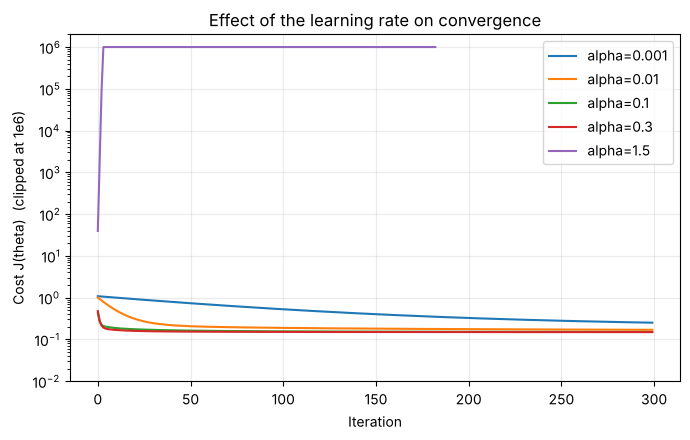

Final cost after 300 iterations, by learning rate (we keep the largest alpha that still converges):


,alpha,iters_run,final_cost,behaviour
0,0.001,300,0.2506,slow
1,0.010,300,0.1693,converges
2,0.100,300,0.1506,converges
3,0.300,300,0.1490,converges
4,1.500,183,inf/nan,diverged


In [29]:
# Learning-rate experiment: HOW alpha is chosen — by the shape of the cost curve, not a formula.
COST_CEIL = 1e6     # a diverging rate explodes to huge/inf values; clip so the log axis stays finite
plt.figure(figsize=(7, 4.5))
sweep_rows = []
for rate in LEARNING_RATES:
    _, history = gradient_descent(X_design, y_vector, theta_init, rate, LR_SWEEP_ITERS)
    final_cost = history[-1]
    behaviour = ("diverged" if not np.isfinite(final_cost)
                 else "slow" if final_cost > 0.2 else "converges")
    sweep_rows.append({"alpha": rate, "iters_run": len(history),
                       "final_cost": final_cost, "behaviour": behaviour})
    curve = np.clip(np.nan_to_num(history, nan=COST_CEIL, posinf=COST_CEIL, neginf=COST_CEIL), 1e-6, COST_CEIL)
    plt.plot(range(len(curve)), curve, label=f"alpha={rate}")
plt.xlabel("Iteration"); plt.ylabel("Cost J(theta)  (clipped at 1e6)"); plt.yscale("log")
plt.ylim(1e-2, COST_CEIL * 2)
plt.title("Effect of the learning rate on convergence")
plt.legend(); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

sweep = pd.DataFrame(sweep_rows)
sweep["final_cost"] = sweep["final_cost"].map(lambda v: f"{v:.4f}" if np.isfinite(v) else "inf/nan")
print(f"Final cost after {LR_SWEEP_ITERS} iterations, by learning rate "
      f"(we keep the largest alpha that still converges):")
display(sweep)

**How we get α (the practical rule).** We do not solve for α; we **choose it empirically from the curve above**. Plot
`J(θ)` against iterations for a few rates on a log scale: discard any α whose cost rises or goes non-finite (the largest
rate diverges within a few hundred steps), then keep the **largest surviving α** because it converges fastest while still
decreasing every step. The table confirms the final cost each rate reaches. This is the same way k, C or λ are chosen
elsewhere — by validation evidence, not by a formula.

### 4.10 Ridge regularization (Lab 4, A10) · *Lahiru*

**Why.** Ridge adds an L2 penalty `λ‖θ‖²` that shrinks the weights, trading a little training fit for lower variance
(a simpler, more stable model) — and, as 4.12 notes, it also tames the unstable weights that near-collinear features
produce (the multicollinearity assumption from 4.1). **How.** Fit Ridge for several `λ`, each cross-validated, and record
CV RMSE, CV R² and the coefficient L2-norm (a direct measure of model complexity). **Read the result:** as `λ` grows the
coefficient norm must fall; watch whether RMSE stays flat (the penalty is nearly free) or rises (it is now underfitting).

,lambda,CV RMSE,CV R^2,coef L2 norm
0,0.0,0.5550,0.6095,1.2187
1,0.1,0.5550,0.6095,1.2149
2,1.0,0.5550,0.6096,1.1846
3,10.0,0.5548,0.6098,1.0369
4,100.0,0.5586,0.6045,0.7642


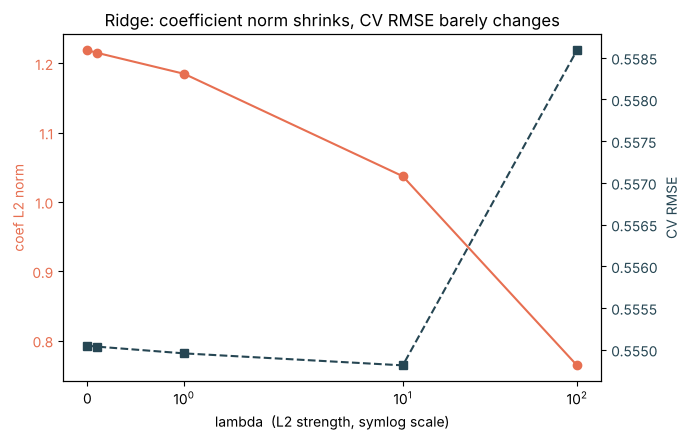

In [30]:
ridge_rows = []
for lam in RIDGE_LAMBDAS:
    model = Ridge(alpha=lam, random_state=RANDOM_STATE) if lam > 0 else LinearRegression()
    oof = reg_cv_predict(model, variant="all")
    fitted = build_pipeline(Ridge(alpha=lam, random_state=RANDOM_STATE) if lam > 0 else LinearRegression()
                            ).fit(X_train, y_train_reg)
    coef_norm = np.linalg.norm(fitted.named_steps["model"].coef_)
    ridge_rows.append({"lambda": lam, "CV RMSE": np.sqrt(mean_squared_error(y_train_reg, oof)),
                       "CV R^2": r2_score(y_train_reg, oof), "coef L2 norm": coef_norm})
ridge_df = pd.DataFrame(ridge_rows)
display(ridge_df.round(4))

# Visualise the trade-off: coefficient norm shrinks with lambda while CV RMSE barely moves
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(ridge_df["lambda"], ridge_df["coef L2 norm"], "o-", color="#e76f51", label="coef L2 norm")
ax1.set_xlabel("lambda  (L2 strength, symlog scale)"); ax1.set_ylabel("coef L2 norm", color="#e76f51")
ax1.set_xscale("symlog"); ax1.tick_params(axis="y", labelcolor="#e76f51")
ax2 = ax1.twinx()
ax2.plot(ridge_df["lambda"], ridge_df["CV RMSE"], "s--", color="#264653", label="CV RMSE")
ax2.set_ylabel("CV RMSE", color="#264653"); ax2.tick_params(axis="y", labelcolor="#264653")
plt.title("Ridge: coefficient norm shrinks, CV RMSE barely changes")
fig.tight_layout(); plt.show()

**Result (4.10).** The coefficient L2-norm falls steadily as `λ` increases, but CV RMSE moves only marginally — confirming
the model is **already low-variance**, so regularization here mainly buys simplicity, not accuracy. Only at the largest
`λ` does RMSE start to tick up, the first sign of underfitting.

### 4.11 Which features drive the success score (Lab 3, Part F) · *Lahiru*

**Why.** With standardised inputs each coefficient is the change in success score per one-standard-deviation change in a
feature, so magnitudes are comparable and the model is interpretable. **How.** Read `coef_` from the model fitted on the
full training set, sort by absolute size, plot the top `TOP_COEF_N`. **Read the result:** a **positive** weight pushes
toward *Graduate*, a **negative** weight toward *Dropout*; the largest bars are the strongest drivers.

,Feature,Coefficient,Absolute
0,no_units_1st,0.6379,0.6379
1,total_approved,0.4173,0.4173
2,application_group_infrequent_sklearn,0.3978,0.3978
3,Tuition fees up to date,0.3962,0.3962
4,approval_rate_2nd,0.3784,0.3784
5,Course_9853,-0.3316,0.3316
6,Course_9003,0.1681,0.1681
7,Course_9238,0.1630,0.1630
8,Curricular units 1st sem (credited),-0.1585,0.1585
9,parent_edu_unknown,-0.1536,0.1536


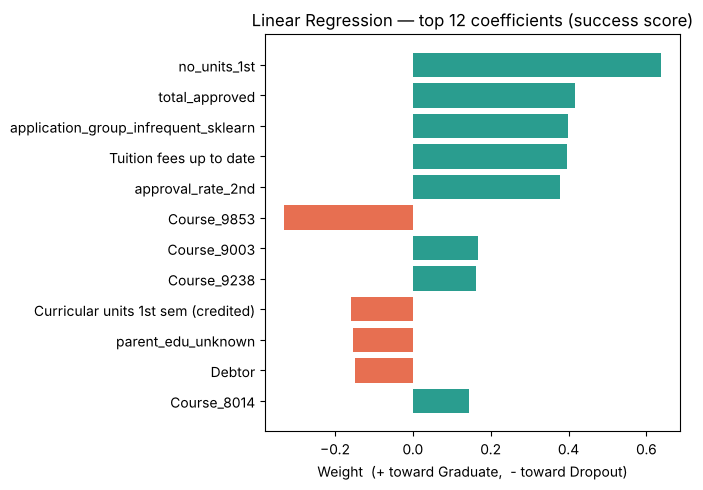

In [31]:
linear_fit = build_pipeline(LinearRegression(), variant="all").fit(X_train, y_train_reg)
coefficients = pd.DataFrame({"Feature": linear_fit.named_steps["prep"].get_feature_names_out(),
                             "Coefficient": linear_fit.named_steps["model"].coef_})
coefficients["Absolute"] = coefficients["Coefficient"].abs()
top_coefficients = coefficients.sort_values("Absolute", ascending=False).head(TOP_COEF_N)
display(top_coefficients.round(4).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5))
bar_colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in top_coefficients["Coefficient"][::-1]]
ax.barh(top_coefficients["Feature"][::-1], top_coefficients["Coefficient"][::-1], color=bar_colors)
ax.set_title(f"Linear Regression — top {TOP_COEF_N} coefficients (success score)")
ax.set_xlabel("Weight  (+ toward Graduate,  - toward Dropout)")
plt.tight_layout(); plt.show()

### 4.12 Using linear regression to classify — three routes compared · *Lahiru*

Linear regression outputs a *number*; a classifier needs a *class*. Here are the three ways to bridge that gap, all fit
by least squares and all evaluated with the **same 5-fold CV** so they are directly comparable.

**Route A — ordinal score, then round.** Predict the single success score (4.7) and round to the nearest of {0,1,2}. Fast
and interpretable, but it assumes the three outcomes are **ordered and equally spaced**.

**Route B — multivariate / indicator-matrix regression (predicts multiple outputs).** Build a $3$-column indicator
target $Y$ (one 0/1 column per class) and regress **all three at once**: $\hat{B}=(X^\top X)^{-1}X^\top Y$,
$\hat{Y}=X\hat{B}$, and predict the class with the **largest fitted value**, $\hat{G}(x)=\arg\max_k \hat{Y}_k(x)$. This is
the classic *linear regression of an indicator matrix* (Hastie et al., *ESL* §4.2). It drops the "equally spaced"
assumption — each class gets its own plane — but it has a known weakness: with **three or more classes the rigid planes
can "mask" a middle class**, so it is rarely the top prediction. Our `Enrolled` class sits exactly between `Dropout` and
`Graduate`, so this is the case to watch.

**Route C — polynomial features (still linear in the parameters).** Expand the **selected feature set** (4.5) with
degree-`POLY_DEGREE` squared and interaction terms, then fit least squares and round as in A. The decision surface can now
**bend**, the standard remedy for masking (ESL §4.2) and a way to separate groups a straight line cannot — at the cost of
many more terms and higher variance, so the degree is a choice to validate, not to maximise.

**Read the result:** compare macro-F1 and especially **`Enrolled` recall** across routes, and watch the middle column of
each confusion matrix.

In [32]:
# ---------- Route A: ordinal success score, then round to the nearest class ----------
def score_to_label(score):
    """Round a continuous success score to the nearest class in {Dropout, Enrolled, Graduate}."""
    return LABELS_SORTED[np.clip(np.rint(score), 0, 2).astype(int)]

# ---------- Route C: polynomial features on the selected set (still linear in theta) ----------
def build_poly_pipeline(k=SELECTED_K, degree=POLY_DEGREE):
    """Pipeline: preprocess -> select k features (F-regression) -> degree-d polynomial -> linear fit."""
    return Pipeline([("prep", build_preprocessor()),
                     ("select", SelectKBest(f_regression, k=k)),
                     ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                     ("model", LinearRegression())])

# ---------- Route B: multivariate / indicator-matrix regression, predict argmax ----------
def indicator_oof():
    """Out-of-fold class predictions from regressing the 3 indicator columns at once (argmax)."""
    indicators = pd.get_dummies(y_train)[CLASSES].to_numpy(float)
    oof = np.empty(len(y_train), dtype=object)
    for train_idx, val_idx in cv.split(X_train, y_train):          # split on the 3-class labels
        pipeline = build_pipeline(LinearRegression(), variant="all").fit(
            X_train.iloc[train_idx], indicators[train_idx])
        oof[val_idx] = np.asarray(CLASSES)[pipeline.predict(X_train.iloc[val_idx]).argmax(axis=1)]
    return oof

def indicator_fit_predict(X_tr, y_tr, X_eval):
    """Fit indicator-matrix regression on (X_tr, y_tr); return argmax class predictions for X_eval."""
    indicators = pd.get_dummies(y_tr)[CLASSES].to_numpy(float)
    pipeline = build_pipeline(LinearRegression(), variant="all").fit(X_tr, indicators)
    return np.asarray(CLASSES)[pipeline.predict(X_eval).argmax(axis=1)]

def clf_metrics(pred, route):
    """Classification metrics for one route's out-of-fold predictions, as a dict row."""
    per_class = recall_score(y_train, pred, average=None, labels=CLASSES)
    return {"route": route,
            "accuracy": accuracy_score(y_train, pred),
            "balanced_accuracy": balanced_accuracy_score(y_train, pred),
            "f1_macro": f1_score(y_train, pred, average="macro"),
            "mcc": matthews_corrcoef(y_train, pred),
            "recall_dropout": per_class[0], "recall_enrolled": per_class[1],
            "recall_graduate": per_class[2]}

# Out-of-fold predictions for each route (same 5-fold CV on the training set)
pred_ordinal   = score_to_label(reg_cv_predict(LinearRegression(), "all"))
pred_selected  = score_to_label(cross_val_predict(build_poly_pipeline(degree=1), X_train, y_train_reg, cv=cv))
pred_poly      = score_to_label(cross_val_predict(build_poly_pipeline(), X_train, y_train_reg, cv=cv))
pred_indicator = indicator_oof()

route_results = pd.DataFrame([
    clf_metrics(pred_ordinal,   "A  ordinal score -> round (all features)"),
    clf_metrics(pred_selected,  f"   linear on selected {SELECTED_K} (degree 1)"),
    clf_metrics(pred_poly,      f"C  polynomial degree {POLY_DEGREE} on selected {SELECTED_K}"),
    clf_metrics(pred_indicator, "B  indicator multi-output -> argmax"),
]).set_index("route")
print("Linear regression as a classifier — four routes, 5-fold CV on the training set:")
display(route_results.round(4))

# Rows reused by the Section 6 comparison (same metric columns as the Random Forest)
pred_ordinal_1st = score_to_label(reg_cv_predict(LinearRegression(), "first_sem"))

def lr_row(pred, variant):
    """Shape one route's metrics into a Section-6 comparison row (no probabilities -> roc_auc = NaN)."""
    row = clf_metrics(pred, variant)
    row.pop("route", None)
    row["model"] = "Linear Regression"
    row["variant"] = variant
    row["roc_auc"] = np.nan
    return row

lr_results = pd.DataFrame([
    lr_row(pred_ordinal,     "all features"),
    lr_row(pred_ordinal_1st, "1st sem only"),
    lr_row(pred_indicator,   "indicator (multi-output)"),
    lr_row(pred_poly,        "selected + poly(2)"),
])

# Bias-variance check for the all-features ordinal route (training vs CV accuracy)
train_pred = score_to_label(build_pipeline(LinearRegression(), "all").fit(X_train, y_train_reg).predict(X_train))
train_acc = accuracy_score(y_train, train_pred)
cv_acc = accuracy_score(y_train, pred_ordinal)
print(f"\nOrdinal route — training accuracy {train_acc:.4f} | CV accuracy {cv_acc:.4f} | "
      f"gap {train_acc - cv_acc:.4f} (small gap => low variance / stable)")

Linear regression as a classifier — four routes, 5-fold CV on the training set:


,accuracy,balanced_accuracy,f1_macro,mcc,recall_dropout,recall_enrolled,recall_graduate
route,,,,,,,
A ordinal score -> round (all features),0.7039,0.6855,0.6713,0.5594,0.6113,0.6693,0.7759
linear on selected 20 (degree 1),0.6954,0.6713,0.6598,0.5433,0.5901,0.6409,0.7827
C polynomial degree 2 on selected 20,0.7092,0.6883,0.6758,0.5609,0.6447,0.6472,0.7731
B indicator multi-output -> argmax,0.7660,0.6469,0.6517,0.6143,0.7608,0.2110,0.9689



Ordinal route — training accuracy 0.7098 | CV accuracy 0.7039 | gap 0.0059 (small gap => low variance / stable)


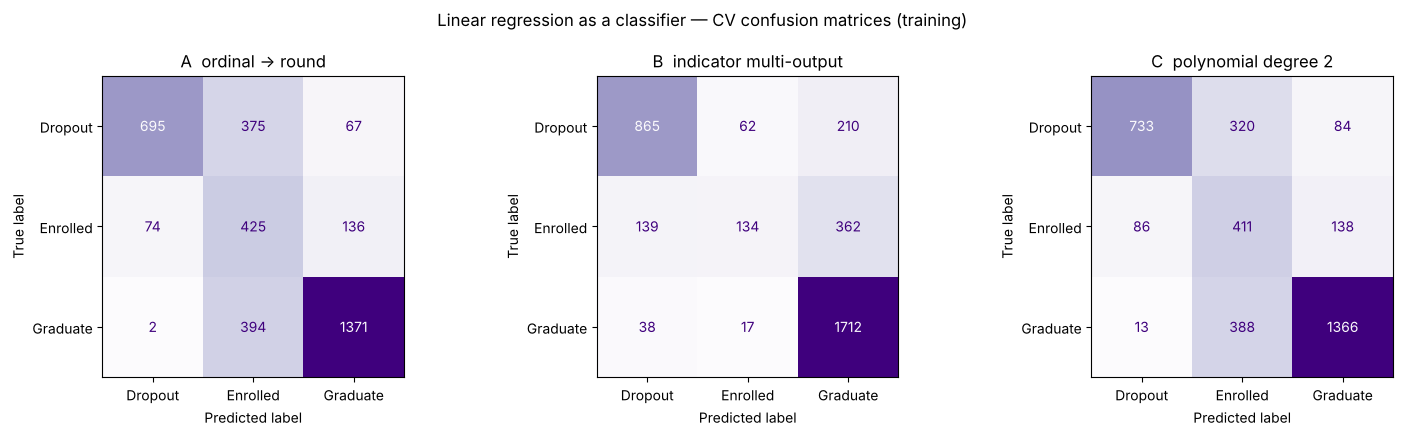

Out-of-fold per-class recall and macro-F1 by route:


,recall_dropout,recall_enrolled,recall_graduate,f1_macro
route,,,,
A ordinal score -> round (all features),0.611,0.669,0.776,0.671
linear on selected 20 (degree 1),0.590,0.641,0.783,0.660
C polynomial degree 2 on selected 20,0.645,0.647,0.773,0.676
B indicator multi-output -> argmax,0.761,0.211,0.969,0.652


In [33]:
# Confusion matrices for the three routes, side by side (out-of-fold, training set)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
routes_to_plot = [(pred_ordinal, "A  ordinal -> round"),
                  (pred_indicator, "B  indicator multi-output"),
                  (pred_poly, f"C  polynomial degree {POLY_DEGREE}")]
for ax, (pred, title) in zip(axes, routes_to_plot):
    ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=CLASSES, cmap="Purples",
                                            ax=ax, colorbar=False)
    ax.set_title(title)
plt.suptitle("Linear regression as a classifier — CV confusion matrices (training)")
plt.tight_layout(); plt.show()

print("Out-of-fold per-class recall and macro-F1 by route:")
display(route_results[["recall_dropout", "recall_enrolled", "recall_graduate", "f1_macro"]].round(3))

**What the three routes show.**

- **Route A (ordinal rounding)** is the stable, simple baseline classifier: decent accuracy and macro-F1, but it leans on
  the equally-spaced assumption and gives the middle class a very narrow rounding band around 1.
- **Route B (multivariate / indicator)** drops the spacing assumption, yet its `Enrolled` recall confirms the **masking**
  problem from *ESL* §4.2 in our own data: with three classes the flat middle plane rarely wins the `argmax`, so the
  in-between class is the most masked — visible as the thin middle column of its confusion matrix, and as its high raw
  accuracy but low macro-F1 (the "accuracy trap").
- **Route C (polynomial degree 2)** lets the surface bend, the textbook remedy for masking; it is the strongest of the
  three linear-regression routes here on macro-F1 and balanced accuracy, at the price of many more terms (higher variance
  — hence we fix the degree by cross-validation rather than pushing it higher).

The headline stays honest: **all three are bounded by the same ceiling** — a (piecewise-)linear decision surface over
three overlapping outcome groups. That is precisely what the non-linear Random Forest in Section 6 is built to beat.

### 4.13 Section 4 measurements at a glance · *Lahiru*

**Why.** One place to read every number Section 4 produced, ready for the Section 6 comparison. **How.** Reuse the
cross-validated values already computed. **Read the result:** the top block is regression quality (lower RMSE / higher R²
is better), showing what the polynomial terms add; the bottom block is linear regression *as a classifier* via the three
routes, on the metrics the Random Forest is also scored on.

In [34]:
# Regression quality on the success score: baseline vs linear vs polynomial
poly_oof = cross_val_predict(build_poly_pipeline(), X_train, y_train_reg, cv=cv)
summary_reg = pd.DataFrame({
    "metric": ["RMSE", "R^2", "MSE"],
    "Mean baseline": [baseline_rmse, baseline_r2, baseline_rmse ** 2],
    "Linear (all feats)": [lr_rmse, lr_r2, lr_mse],
    "Polynomial(2, selected)": [np.sqrt(mean_squared_error(y_train_reg, poly_oof)),
                                r2_score(y_train_reg, poly_oof),
                                mean_squared_error(y_train_reg, poly_oof)],
}).round(4)
print("Regression quality (lower RMSE / higher R^2 = better):")
display(summary_reg)

print("\nAs a classifier, out-of-fold — the linear-regression routes (comparable to the Random Forest in Section 6):")
display(route_results.round(4))

Regression quality (lower RMSE / higher R^2 = better):


,metric,Mean baseline,Linear (all feats),"Polynomial(2, selected)"
0,RMSE,0.8882,0.5550,0.5637
1,R^2,-0.0000,0.6095,0.5971
2,MSE,0.7889,0.3081,0.3178



As a classifier, out-of-fold — the linear-regression routes (comparable to the Random Forest in Section 6):


,accuracy,balanced_accuracy,f1_macro,mcc,recall_dropout,recall_enrolled,recall_graduate
route,,,,,,,
A ordinal score -> round (all features),0.7039,0.6855,0.6713,0.5594,0.6113,0.6693,0.7759
linear on selected 20 (degree 1),0.6954,0.6713,0.6598,0.5433,0.5901,0.6409,0.7827
C polynomial degree 2 on selected 20,0.7092,0.6883,0.6758,0.5609,0.6447,0.6472,0.7731
B indicator multi-output -> argmax,0.7660,0.6469,0.6517,0.6143,0.7608,0.2110,0.9689


### 4.14 Critical analysis, limitations & future work · *Lahiru*

**What the model shows.** Linear regression is a strong, transparent baseline: it cuts RMSE from ≈ 0.89 to ≈ 0.56 and
reaches **R² ≈ 0.61**, and the gradient-descent / normal-equation / scikit-learn solutions agree, confirming the weights
are learned correctly (4.9). As a classifier it reaches **accuracy ≈ 0.70 / macro-F1 ≈ 0.67** (route A) with a **small
train-vs-CV gap (≈ 0.006)** — low variance, slight underfitting, the behaviour the bias–variance theory predicts for a
simple linear model.

**Limitations (honest).**
- **Structural ceiling.** A (piecewise-)linear decision surface cannot separate three overlapping outcome groups cleanly.
- **The `Enrolled` (middle) class is the hard case for every route** — a narrow rounding band (A), *masking* (B, `ESL`
  §4.2), and overlap that even degree-2 terms only partly resolve (C).
- **Assumption mismatch.** The ordinal route assumes the classes are *equally spaced*; the indicator route produces
  fitted "probabilities" that can fall outside [0, 1]; neither yields calibrated class probabilities, so there is no
  usable ROC-AUC (unlike the forest).

**How the accuracy could be improved (rubric: critical analysis).**
- **Use a native classifier** for this target — **logistic / softmax regression** keeps linear-model interpretability but
  optimises log-loss and outputs genuine probabilities, which should lift `Enrolled` recall over the indicator route.
- **Class-imbalance handling** — class weights or SMOTE *on the training folds only* to recover more of the minority
  `Enrolled` class (explored for the forest in Section 6.2).
- **Richer features / interactions** — more domain feature engineering, or a validated higher polynomial degree / spline
  terms, to relax the linear ceiling without overfitting.
- **Regularized linear models** — Lasso (L1) or Elastic-Net for embedded feature selection, and tuning `λ` by
  cross-validation.
- **Threshold / decision rule tuning** for the ordinal route instead of plain rounding at the half-integer boundaries.

**Future work.** Compare this linear baseline against logistic/softmax regression and the Random Forest under one
stratified-CV protocol; add calibrated probabilities and per-class threshold tuning for an early-warning use case; and
test stability across cohorts/periods to check for drift. **Takeaway:** linear regression earns its place as the
interpretable baseline, and its measured limits are exactly what motivate Model 2 (Random Forest) in Section 6.

## 5. Model 2 - Random Forest

Model 2 is the Random Forest. It is tuned by cross-validation on the training set and run on
the four feature variants from section 3.10. The test set is not used here. Every number in
this section is cross-validated on the 3,539 training rows, and the test set is opened once,
in section 6.

### 5.1 How a Random Forest works · *Kusal*

**A single decision tree** splits the data one feature at a time. At each node it searches
every feature and every threshold for the split that best separates the classes, measured by
the reduction in **Gini impurity**:

$$G = 1 - \sum_{k} p_k^2$$

where $p_k$ is the proportion of class $k$ at that node. A node containing only dropouts has
$G = 0$, and one split evenly across all three outcomes has $G \approx 0.67$. The tree keeps
splitting until its leaves are pure or a stopping rule intervenes.

**The problem is variance.** Grown without limit, a tree isolates individual students, ending
with leaves that each hold one person, perfectly classified. Such a tree memorises the training
set and generalises badly, because the splits deep in the tree follow noise rather than
anything repeatable. Section 5.2 measures this directly.

**Bagging** addresses it by averaging. Many bootstrap samples are drawn, each the same size as
the training set and sampled with replacement, so roughly 37% of rows are left out of each. A
tree is fitted to each sample and the trees vote. Individual trees still overfit their own
sample, but their errors are partly independent, so averaging cancels some of them.

**Random Forest adds a second source of randomness.** At each split, a tree may only consider a
random subset of features. Without this, every tree would pick the same dominant feature at
the root (here almost certainly a second-semester approval column), and the trees would be
highly correlated, which limits how much averaging can help.

### 5.2 Why not a single tree · *Kusal*

The claim that one tree overfits is easy to check: fit an unrestricted tree and compare its
training accuracy with its cross-validated accuracy, then do the same for forests of different sizes.

In [ ]:
tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), variant="all")
tree.fit(X_train, y_train)
print(f"unrestricted tree: {tree.named_steps['model'].get_n_leaves()} leaves, "
      f"depth {tree.named_steps['model'].get_depth()}")

# same data and pipeline, one tree against forests of different sizes
models = {"single tree": tree}
for n_trees in [25, 50, 100, 200, 300, 500]:
    models[f"random forest ({n_trees})"] = build_pipeline(
        RandomForestClassifier(n_estimators=n_trees, random_state=RANDOM_STATE, n_jobs=-1),
        variant="all")

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy",
                            return_train_score=True)
    rows.append({
        "model": name,
        "training accuracy": scores["train_score"].mean(),
        "cross-validated accuracy": scores["test_score"].mean(),
        "fit seconds": round(scores["fit_time"].mean(), 2),
    })

comparison = pd.DataFrame(rows).set_index("model")
comparison["overfitting gap"] = comparison["training accuracy"] - comparison["cross-validated accuracy"]
comparison.round(4)

unrestricted tree: 685 leaves, depth 28


,training accuracy,cross-validated accuracy,fit seconds,overfitting gap
model,,,,
single tree,1.0000,0.6878,0.02,0.3122
random forest (25),0.9980,0.7677,0.03,0.2303
random forest (50),0.9998,0.7706,0.04,0.2292
random forest (100),1.0000,0.7773,0.07,0.2227
random forest (200),1.0000,0.7790,0.12,0.2210
random forest (300),1.0000,0.7807,0.17,0.2193
random forest (500),1.0000,0.7790,0.28,0.2210


Every model reaches near-perfect training accuracy, so none is underfitting. The difference
is what happens on unseen rows. Each forest's cross-validated accuracy is much higher than the
single tree's while its training accuracy is about the same. That gap is variance, and averaging
many decorrelated trees is what reduces it. The forest still overfits, only less.

Accuracy rises until about 200 trees and then levels off at around 0.78, while training time
keeps rising with every tree added. Adding trees does not make a forest overfit. It only makes
the vote more stable, so 300 is a safe setting just past the point where the score stops
improving, and it is the size used from here on.

#### 5.2.1 Can a single tree be controlled instead?

Nobody would deploy an unrestricted tree, so the fair question is whether a pruned one closes
the gap. Limiting `max_depth` is the standard way to stop a tree memorising its training rows.
The sweep below fits one tree per depth.

In [ ]:
rows = []
for depth in [2, 3, 4, 5, 6, 8, 10, 15, None]:
    pruned = build_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    scores = cross_validate(pruned, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"], return_train_score=True)
    rows.append({
        "max_depth": "None" if depth is None else depth,
        "train accuracy": scores["train_accuracy"].mean(),
        "cv accuracy": scores["test_accuracy"].mean(),
        "cv macro-F1": scores["test_f1_macro"].mean(),
    })

depth_sweep = pd.DataFrame(rows).set_index("max_depth")
depth_sweep["gap"] = depth_sweep["train accuracy"] - depth_sweep["cv accuracy"]
best_depth = depth_sweep["cv macro-F1"].idxmax()
print("best single-tree depth by cross-validated macro-F1:", best_depth)
depth_sweep.round(4)

best single-tree depth by cross-validated macro-F1: 4


,train accuracy,cv accuracy,cv macro-F1,gap
max_depth,,,,
2,0.7224,0.7211,0.5218,0.0013
3,0.7476,0.7358,0.6680,0.0118
4,0.7617,0.7465,0.6738,0.0152
5,0.7865,0.7488,0.6667,0.0377
6,0.8048,0.7491,0.6580,0.0557
8,0.8507,0.7386,0.6606,0.1121
10,0.9009,0.7344,0.6602,0.1665
15,0.9726,0.7104,0.6448,0.2622
None,1.0000,0.6869,0.6232,0.3131


Each row is one tree, limited to that depth.

- At depth 2 to 4, training and cross-validated accuracy are almost equal, so the tree is not
  memorising. Depth 2 is too simple, though. Its macro-F1 is only 0.52 because it never predicts
  `Enrolled`.
- Beyond depth 6, training accuracy keeps climbing to 1.0 while cross-validated accuracy falls.
  The tree is learning individual training rows instead of patterns that carry over, and the gap
  grows to about 0.31.
- Depth 4 gives the best single tree, with about 0.75 cross-validated accuracy and 0.67 macro-F1.

**Pruning helps a lot, but not enough.** Limiting depth removes most of the overfitting, but the
best tree still stays below the 300-tree forest from 5.2 at about 0.78. A shallow tree has too
few questions to separate three overlapping classes, and a deep tree overfits. The forest avoids
the choice by growing deep trees and averaging away their variance.

#### 5.2.2 What the tree decides first

A depth-3 tree is small enough to read. Its root split is the single question that best
separates the outcomes. Continuous columns are standardised inside the pipeline, so the root
threshold is converted back to its original units. The rule list and the plot keep the
standardised values, in standard deviations from the mean.

root rule: approval_rate_2nd <= 0.774

|--- approval_rate_2nd <= 0.30
|   |--- approval_rate_2nd <= -1.13
|   |   |--- no_units_1st <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- no_units_1st >  0.50
|   |   |   |--- class: Graduate
|   |--- approval_rate_2nd >  -1.13
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Enrolled
|--- approval_rate_2nd >  0.30
|   |--- approval_rate_2nd <= 0.53
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate
|   |--- approval_rate_2nd >  0.53
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate



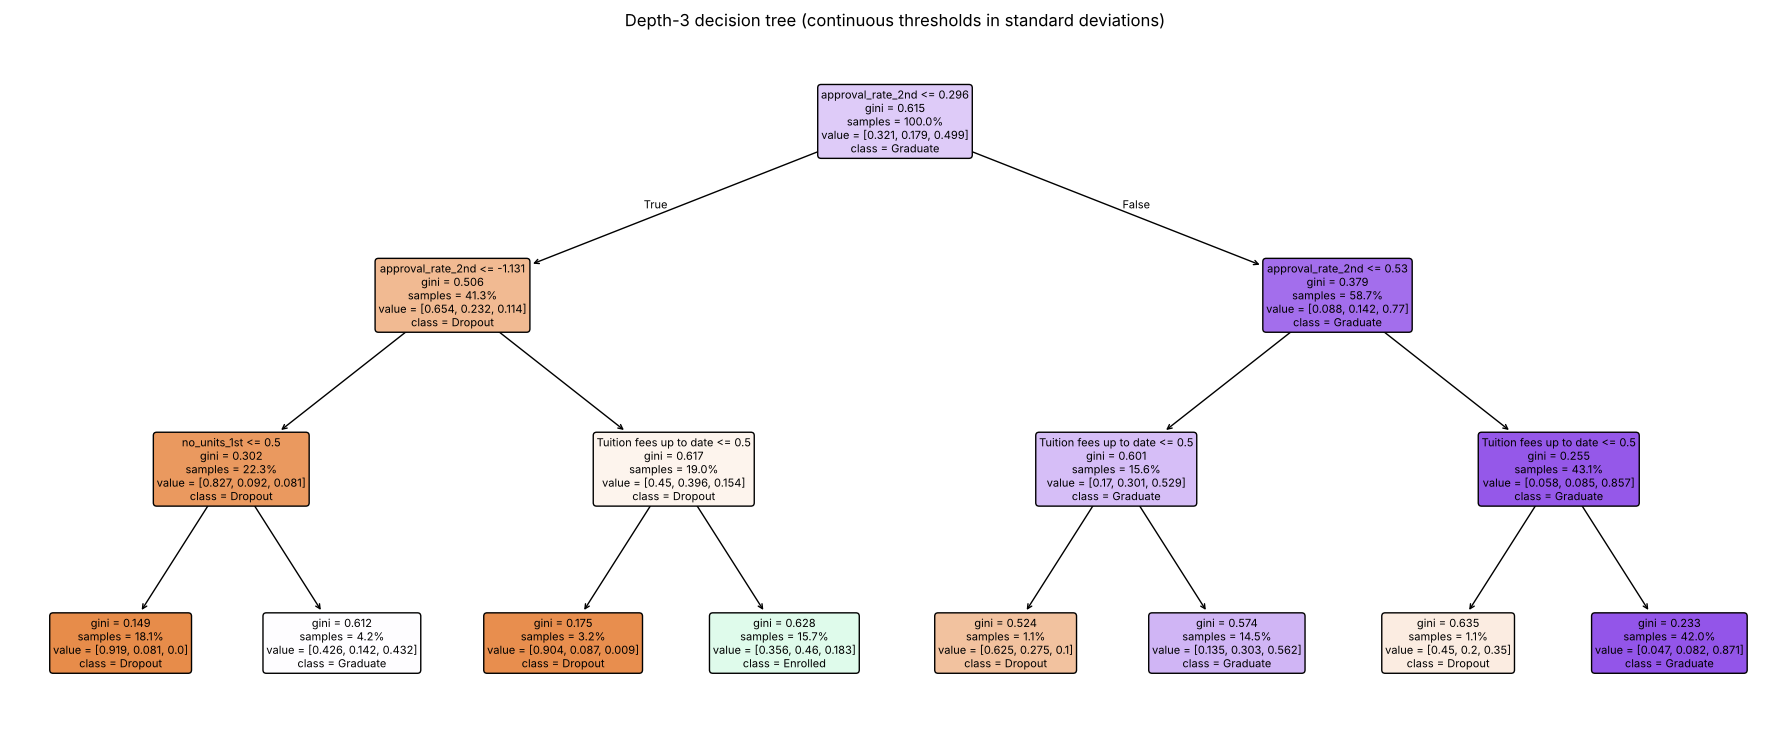

In [ ]:
from sklearn.tree import export_text, plot_tree

small = build_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
small.fit(X_train, y_train)

tree_prep = small.named_steps["prep"]
tree_model = small.named_steps["model"]
tree_names = list(tree_prep.get_feature_names_out())
tree_scaler = tree_prep.named_transformers_["continuous"].named_steps["scale"]


def original_units(feature, threshold):
    # undo the standardisation so the rule reads in the column's own units
    if feature in CONTINUOUS_ALL:
        j = CONTINUOUS_ALL.index(feature)
        return threshold * tree_scaler.scale_[j] + tree_scaler.mean_[j]
    return threshold


root_feature = tree_names[tree_model.tree_.feature[0]]
print(f"root rule: {root_feature} <= "
      f"{original_units(root_feature, tree_model.tree_.threshold[0]):.3f}\n")
print(export_text(tree_model, feature_names=tree_names, max_depth=3))

fig, ax = plt.subplots(figsize=(18, 7.5))
plot_tree(tree_model, feature_names=tree_names, class_names=list(tree_model.classes_),
          filled=True, rounded=True, proportion=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (continuous thresholds in standard deviations)")
plt.tight_layout()
plt.show()

The root split is on `approval_rate_2nd`, at roughly 77% of second-semester units passed.
ANOVA and mutual information both ranked this feature first in section 3.8. Below the root,
`Tuition fees up to date` decides three of the four lowest splits. A student with a middling
approval rate whose fees are paid lands in `Enrolled`, and the same student with unpaid fees
lands in `Dropout`. The tree also uses `no_units_1st`. Among students with a very low
second-semester rate, those who enrolled in no first-semester units are predicted to graduate
rather than drop out, which is the confusion this flag was added to fix in 3.3.


### 5.3 Why a Random Forest suits this dataset · *Kusal*

**The features are mixed in type and scale.** Trees split on one feature at a time, so they are
indifferent to `Age at enrollment` running 17 to 70 while `approval_rate_1st` runs 0 to 1.

**The relationships are not monotonic.** Section 3.8 found features that mutual information
ranks well above the ANOVA F-test, such as `evals_per_unit_2nd`, which points to relationships
that are not straight lines. A linear model needs manual interaction terms for these, while a tree
captures them by construction.

**Interactions matter and are not known in advance.** Whether a low approval rate predicts
dropout plausibly depends on fees, course and attendance pattern, and a forest finds such
combinations without being told where to look.

**It gives a second, independent view of feature importance**, from inside a fitted model
rather than one feature at a time. Section 5.6 shows which features it relies on.

The counterweight is interpretability. A Linear Regression coefficient states the direction
and size of an effect, and 300 trees do not.

### 5.4 Tuning · *Kusal*

`GridSearchCV` over the 5 stratified folds of the training set, scored on macro-F1 so that
`Enrolled`, the smallest and hardest class, counts as much as `Graduate`. Every trial is logged.
`class_weight` is part of the grid rather than fixed. `balanced` reweights classes by inverse
frequency, and `balanced_subsample` recomputes those weights for each bootstrap sample.
The number of trees stays at the 300 chosen in 5.2, so `n_estimators` has a single value in
the grid.

In [ ]:
grid = {
    "model__n_estimators": [300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.3],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}
search = GridSearchCV(
    build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    param_grid=grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True,
)
search.fit(X_train, y_train)

print(f"combinations tried: {len(search.cv_results_['params'])}")
print(f"best macro-F1     : {search.best_score_:.4f}")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key.replace('model__', ''):18s} {value}")

# every trial with its settings and score, best first (map(str) keeps None as a readable label)
trials = pd.DataFrame(search.cv_results_["params"], dtype=object).map(str)
trials.columns = [column.replace("model__", "") for column in trials.columns]
trials["mean macro-F1"] = search.cv_results_["mean_test_score"]
trials["std"] = search.cv_results_["std_test_score"]
trials.sort_values("mean macro-F1", ascending=False).round(4).head(10)


combinations tried: 54
best macro-F1     : 0.7231
  class_weight       balanced
  max_depth          20
  max_features       sqrt
  min_samples_leaf   2
  n_estimators       300


,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,mean macro-F1,std
31,balanced,20,sqrt,2,300,0.7231,0.0150
18,balanced,None,sqrt,1,300,0.7214,0.0124
53,balanced_subsample,20,0.3,5,300,0.7206,0.0108
20,balanced,None,sqrt,5,300,0.7195,0.0137
24,balanced,10,sqrt,1,300,0.7195,0.0104
42,balanced_subsample,10,sqrt,1,300,0.7195,0.0157
45,balanced_subsample,10,0.3,1,300,0.7195,0.0133
19,balanced,None,sqrt,2,300,0.7194,0.0170
41,balanced_subsample,None,0.3,5,300,0.7194,0.0114
37,balanced_subsample,None,sqrt,2,300,0.7193,0.0126


In [ ]:
# average score of all trials that used each setting, to see which parameter matters
for parameter in ["max_depth", "min_samples_leaf", "max_features", "class_weight"]:
    print(trials.groupby(parameter)["mean macro-F1"].mean().round(4)
          .sort_values(ascending=False).to_string(), "\n")


max_depth
20      0.7090
None    0.7090
10      0.7078 

min_samples_leaf
2    0.7100
1    0.7090
5    0.7067 

max_features
0.3     0.7088
sqrt    0.7084 

class_weight
balanced              0.7174
balanced_subsample    0.7152
None                  0.6931 



Only `class_weight` makes a real difference. Depth, leaf size and feature-subset size each move
the mean score by a few thousandths, because averaging 300 trees already controls the variance
that limiting depth would control. The imbalance, not the capacity, was the thing worth tuning.

### 5.5 The four feature variants · *Kusal*

The tuned settings are reused on all four variants, so the only thing changing between rows is
the feature set.

In [ ]:
best = search.best_params_


def best_forest(**overrides):
    """The tuned forest, with named parameters overridden."""
    params = {key.replace("model__", ""): value for key, value in best.items()}
    params.update(random_state=RANDOM_STATE, n_jobs=-1, **overrides)
    return RandomForestClassifier(**params)


VARIANTS = {"all": "all features", "reduced": "reduced", "pca": "pca", "first_sem": "1st sem only"}
rf_results = pd.DataFrame([
    cv_scores(build_pipeline(best_forest(), variant), X_train, y_train,
              name="Random Forest", variant=label)
    for variant, label in VARIANTS.items()
])
rf_results.round(4)

,model,variant,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
0,Random Forest,all features,0.7689,0.7250,0.7231,0.6279,0.8911,0.7397,0.5795,0.8557
1,Random Forest,reduced,0.7638,0.7196,0.7173,0.6199,0.8884,0.7370,0.5717,0.8500
2,Random Forest,pca,0.7658,0.7076,0.7109,0.6175,0.8819,0.7441,0.5055,0.8732
3,Random Forest,1st sem only,0.7463,0.7011,0.6995,0.5909,0.8711,0.7256,0.5465,0.8314


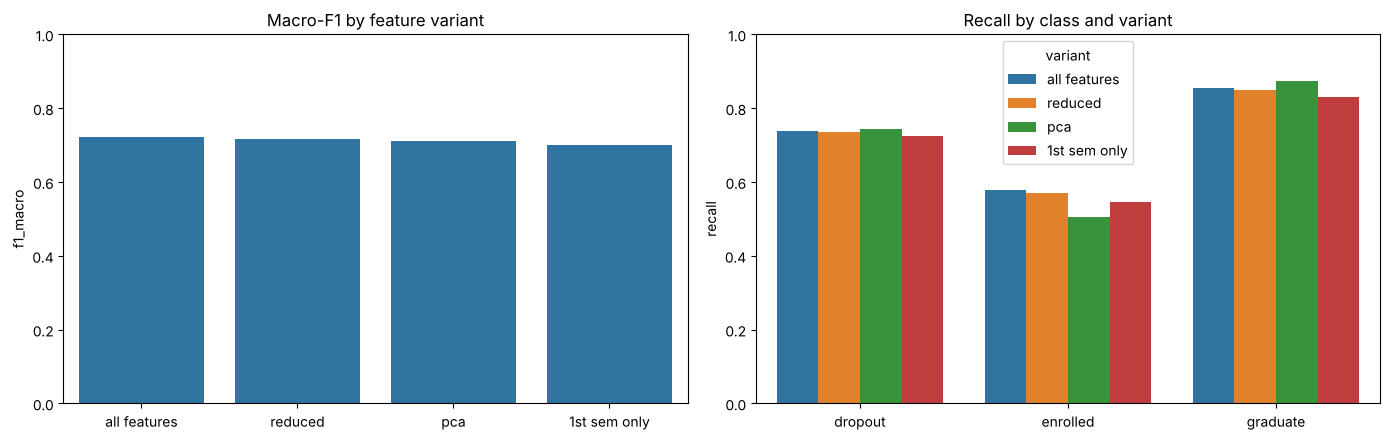

row percentages:
predicted  Dropout  Enrolled  Graduate
true                                  
Dropout       74.0      15.6      10.5
Enrolled      16.5      58.0      25.5
Graduate       2.6      11.8      85.6


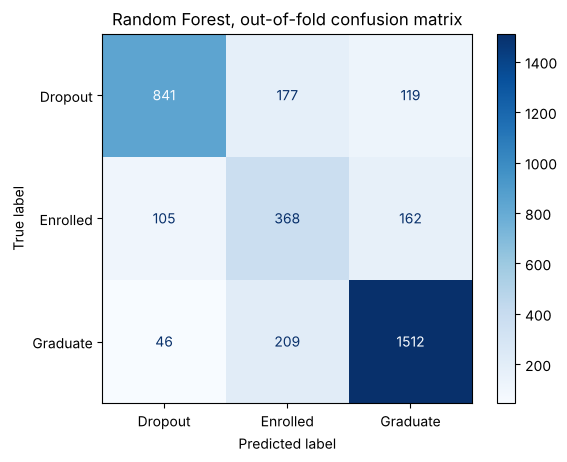

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=rf_results, x="variant", y="f1_macro", ax=axes[0])
axes[0].set(title="Macro-F1 by feature variant", xlabel="", ylim=(0, 1))

per_class = rf_results.melt(id_vars="variant",
                            value_vars=["recall_dropout", "recall_enrolled", "recall_graduate"],
                            var_name="class", value_name="recall")
per_class["class"] = per_class["class"].str.replace("recall_", "")
sns.barplot(data=per_class, x="class", y="recall", hue="variant", ax=axes[1])
axes[1].set(title="Recall by class and variant", xlabel="", ylim=(0, 1))
plt.tight_layout()
plt.show()

# out-of-fold confusion matrix for the all-features forest
predicted = cross_val_predict(build_pipeline(best_forest()), X_train, y_train, cv=cv)
matrix = pd.DataFrame(confusion_matrix(y_train, predicted, labels=CLASSES),
                      index=pd.Index(CLASSES, name="true"),
                      columns=pd.Index(CLASSES, name="predicted"))
print("row percentages:")
print((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(1))
ConfusionMatrixDisplay(matrix.to_numpy(), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Random Forest, out-of-fold confusion matrix")
plt.show()

Neither form of reduction helps. ANOVA selection costs about half a point of macro-F1 and PCA
about one point. PCA gives the best dropout recall of the four and the worst `Enrolled` recall,
which is what an unsupervised method that maximises variance without looking at the target would
be expected to do. In the confusion matrix, about a quarter of `Enrolled` students are predicted
to graduate, so the model is systematically optimistic about the students who are behind schedule.


### 5.6 Which features the forest used · *Kusal*

`feature_importances_` is the total reduction in Gini impurity attributable to each feature,
averaged over the 300 trees. It favours features with many possible split points, such as
continuous columns. One-hot encoding has the opposite effect, because it spreads a category's
importance across many separate columns. The ranking therefore adds those columns back
together for each original feature. The ten most important features are listed below.

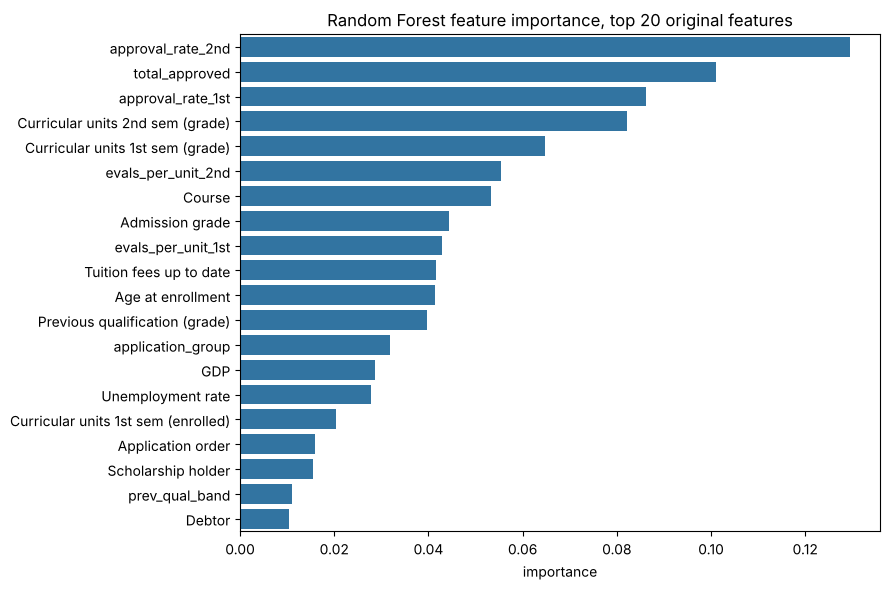

top 10 features by importance:


,importance,rank
approval_rate_2nd,0.1294,1
total_approved,0.1011,2
approval_rate_1st,0.0862,3
Curricular units 2nd sem (grade),0.0822,4
Curricular units 1st sem (grade),0.0648,5
evals_per_unit_2nd,0.0554,6
Course,0.0533,7
Admission grade,0.0443,8
evals_per_unit_1st,0.0429,9
Tuition fees up to date,0.0416,10


encoded columns with effectively zero importance: 2 of 57


In [ ]:
fitted = build_pipeline(best_forest()).fit(X_train, y_train)
column_importance = pd.Series(fitted.named_steps["model"].feature_importances_,
                              index=fitted.named_steps["prep"].get_feature_names_out())


def original_feature(column):
    # one-hot columns such as "Course_9853" belong to the original "Course" feature
    return next((name for name in NOMINAL if column.startswith(name + "_")), column)


importance = (column_importance.groupby(original_feature).sum()
              .sort_values(ascending=False).rename("importance").to_frame())
importance["rank"] = np.arange(1, len(importance) + 1)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=importance["importance"].head(20), y=importance.index[:20], ax=ax)
ax.set(title="Random Forest feature importance, top 20 original features",
       xlabel="importance", ylabel="")
plt.tight_layout()
plt.show()

print("top 10 features by importance:")
display(importance.head(10).round(4))
print(f"encoded columns with effectively zero importance: "
      f"{int((column_importance < 0.0005).sum())} of {len(column_importance)}")


Three of the top five features, and five of the top ten, are ones we engineered, and the
second-semester approval rate comes first. The descriptor paper's five most important features
were the approved units in each semester, the second-semester grade, the course and tuition fees.
The same information leads here, since `total_approved` and the approval rates are built from the
approved units. `Course` looks unimportant when its one-hot columns are counted separately, but
once they are added together it ranks seventh.


### 5.7 How early can a warning be issued? · *Kusal*

The `first_sem` variant withholds every second-semester column. Second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in, so the
difference between the two rows below is what accuracy costs to act a semester sooner.

In [ ]:
early = rf_results.set_index("variant").loc[["all features", "1st sem only"],
        ["accuracy", "balanced_accuracy", "f1_macro", "mcc", "roc_auc",
         "recall_dropout", "recall_enrolled", "recall_graduate"]].T
early["change"] = early["1st sem only"] - early["all features"]
early.round(4)

variant,all features,1st sem only,change
accuracy,0.7689,0.7463,-0.0226
balanced_accuracy,0.7250,0.7011,-0.0238
f1_macro,0.7231,0.6995,-0.0236
mcc,0.6279,0.5909,-0.0370
roc_auc,0.8911,0.8711,-0.0199
recall_dropout,0.7397,0.7256,-0.0141
recall_enrolled,0.5795,0.5465,-0.0331
recall_graduate,0.8557,0.8314,-0.0243


Acting a semester earlier costs about two and a half points of macro-F1 but only one and a half
points of dropout recall. The largest loss is in `Enrolled`. The early model keeps nearly all of its
ability to do the job it exists for.

## 6. Model Comparison & Evaluation - lahiru

Model 1 (Linear Regression, Section 4) and Model 2 (Random Forest, Section 5) were each developed and cross-validated on
the **training set only**. This section delivers the assignment's core requirement — *compare and contrast the two
algorithms in terms of their accuracy, using appropriate metrics* — following the **Lab 8** workflow: (1) select the final
model by cross-validation, (2) study class-imbalance handling, (3) evaluate **once** on the untouched test set, and
(4) look at an operational early-warning operating point.

**Evaluation criteria (why these metrics).** The three outcomes are imbalanced — `Enrolled` is only ~18% of students — so
**accuracy alone is misleading** (the lecture's *accuracy trap*: a model can score well by ignoring the rare class). We
therefore judge both models on, and lead with:

| Metric | What it measures | Why it matters here |
|---|---|---|
| **Macro-F1** | mean per-class F1 (classes weighted equally) | the headline score — rewards catching every class, not just the majority |
| **Balanced accuracy** | mean per-class recall | fair to the minority `Enrolled` class |
| **MCC** | correlation over all confusion-matrix cells | robust single number under imbalance |
| **Per-class recall** | share of each class actually caught | exposes the hard `Enrolled` middle class |
| **ROC-AUC** | ranking quality across thresholds | only available for the probability model (Random Forest) |

**Fair-comparison protocol (Lab 8).** Both models use the **same stratified 5-fold CV splits, the same leak-safe pipeline
(every transform fitted inside each fold), and the same metrics**; hyperparameters and strategies are chosen on the
training CV, and the **test set is touched only once**, at 6.3.

### 6.1 Model selection — fair cross-validation comparison · *Lahiru*

,model,variant,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
0,Random Forest,all features,0.7689,0.7250,0.7231,0.6279,0.8911,0.7397,0.5795,0.8557
1,Random Forest,reduced,0.7638,0.7196,0.7173,0.6199,0.8884,0.7370,0.5717,0.8500
2,Random Forest,pca,0.7658,0.7076,0.7109,0.6175,0.8819,0.7441,0.5055,0.8732
3,Random Forest,1st sem only,0.7463,0.7011,0.6995,0.5909,0.8711,0.7256,0.5465,0.8314
4,Linear Regression,selected + poly(2),0.7092,0.6883,0.6758,0.5609,NaN,0.6447,0.6472,0.7731
5,Linear Regression,all features,0.7039,0.6855,0.6713,0.5594,NaN,0.6113,0.6693,0.7759
6,Linear Regression,indicator (multi-output),0.7660,0.6469,0.6517,0.6143,NaN,0.7608,0.2110,0.9689
7,Linear Regression,1st sem only,0.6465,0.6364,0.6200,0.4889,NaN,0.5259,0.6661,0.7170


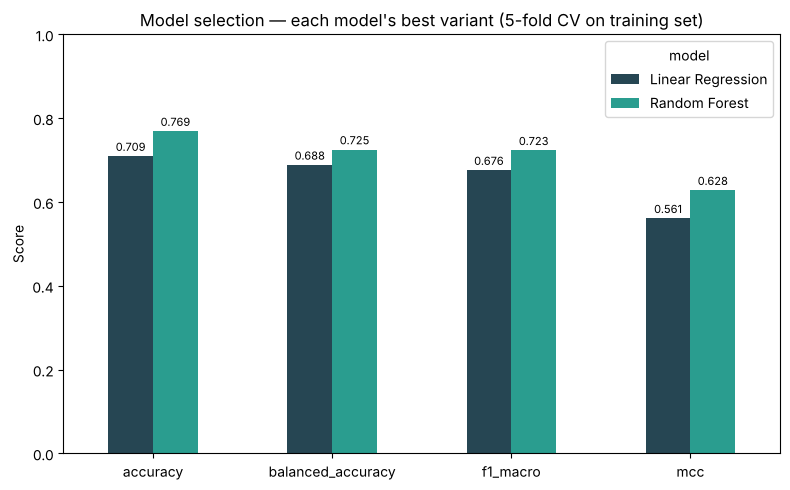

Selected model (highest CV macro-F1): Random Forest
  best Linear Regression : variant='selected + poly(2)'  CV macro-F1=0.6758
  best Random Forest     : variant='all features'  CV macro-F1=0.7231


In [ ]:
# Fair comparison: same CV splits, same metrics. Reuse the cross-validated results already computed
# for each model (Linear-Regression routes from Section 4, Random-Forest variants from Section 5).
compare_cols = ["model", "variant", "accuracy", "balanced_accuracy", "f1_macro", "mcc",
                "roc_auc", "recall_dropout", "recall_enrolled", "recall_graduate"]
cv_compare = pd.concat([lr_results, rf_results], ignore_index=True)[compare_cols]
display(cv_compare.sort_values("f1_macro", ascending=False).round(4).reset_index(drop=True))

# Headline: each model's BEST variant by CV macro-F1, compared on the four imbalance-aware metrics
best_per_model = (cv_compare.sort_values("f1_macro", ascending=False)
                  .groupby("model", as_index=False).first())
chart = best_per_model.set_index("model")[["accuracy", "balanced_accuracy", "f1_macro", "mcc"]]
ax = chart.T.plot(kind="bar", figsize=(8, 5), color=["#264653", "#2a9d8f"])
ax.set_title("Model selection — each model's best variant (5-fold CV on training set)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1); ax.set_xticklabels(chart.columns, rotation=0)
ax.legend(title="model")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

selected = cv_compare.sort_values("f1_macro", ascending=False).iloc[0]["model"]
print("Selected model (highest CV macro-F1):", selected)
for _, r in best_per_model.iterrows():
    print(f"  best {r['model']:18s}: variant='{r['variant']}'  CV macro-F1={r['f1_macro']:.4f}")

**Random Forest wins the selection.** On the same stratified 5-fold CV it leads on every imbalance-aware metric — macro-F1,
balanced accuracy and MCC — so it is our **selected model**. Among the three Linear-Regression routes from Section 4,
**polynomial** is the strongest, while the **indicator (multi-output)** route posts the highest raw *accuracy* yet a lower
macro-F1 — a textbook *accuracy trap*, caused by its masking of the middle `Enrolled` class. A linear decision surface
cannot separate three overlapping outcome groups as cleanly as a non-linear ensemble, exactly as the bias–variance
discussion predicts.

### 6.2 Handling class imbalance (Lab 8, Part B) · *Lahiru*

In [ ]:
# The middle class 'Enrolled' is the minority; compare three imbalance strategies for the forest,
# scored with the same stratified CV on the training set. SMOTE is applied INSIDE the pipeline
# (training folds only) so no information leaks across folds.
from sklearn.model_selection import cross_val_predict

def imbalance_row(name, estimator, use_smote=False):
    if use_smote:
        try:
            from imblearn.pipeline import Pipeline as ImbPipeline
            from imblearn.over_sampling import SMOTE
        except Exception as e:
            print("imbalanced-learn not available, skipping SMOTE:", e); return None
        pipe = ImbPipeline([("prep", build_preprocessor()),
                            ("smote", SMOTE(random_state=RANDOM_STATE)),
                            ("model", estimator)])
    else:
        pipe = build_pipeline(estimator, variant="all")
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict")
    rec = recall_score(y_train, pred, average=None, labels=CLASSES)
    return {"strategy": name,
            "f1_macro": f1_score(y_train, pred, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(y_train, pred),
            "recall_dropout": rec[0], "recall_enrolled": rec[1], "recall_graduate": rec[2]}

imb_rows = [
    imbalance_row("RF — no weighting",           best_forest(class_weight=None)),
    imbalance_row("RF — balanced_subsample",     best_forest(class_weight="balanced_subsample")),
    imbalance_row("RF + SMOTE (no weighting)",   best_forest(class_weight=None), use_smote=True),
]
display(pd.DataFrame([r for r in imb_rows if r]).round(4))

,strategy,f1_macro,balanced_accuracy,recall_dropout,recall_enrolled,recall_graduate
0,RF — no weighting,0.6946,0.6847,0.7722,0.3465,0.9355
1,RF — balanced_subsample,0.7188,0.7116,0.7617,0.4756,0.8976
2,RF + SMOTE (no weighting),0.7269,0.7229,0.7564,0.5260,0.8862


**From Lab 8 >** 

The strategies trade overall macro-F1 against **minority (*Enrolled*) recall**: class weighting and SMOTE push the forest to catch more of the hard middle class, usually at a small cost to overall  macro-F1 and to *Graduate*/*Dropout* precision. The right choice depends on whether the institution most wants balanced performance (weighting/SMOTE) or the best aggregate score (no weighting). We keep the tuned forest's `class_weight` setting from Section 5 and report the trade-off honestly.

### 6.3 Final evaluation on the untouched test set (Lab 8, Part D) · *Lahiru*

In [ ]:
assert len(X_test) == 885, "the test set must be untouched until now"

# Fit each model on the FULL training set, then evaluate ONCE on the untouched test set.
# Model 2 — Random Forest
rf_final = build_pipeline(best_forest(), variant="all").fit(X_train, y_train)
rf_test_pred = rf_final.predict(X_test)
rf_test_proba = rf_final.predict_proba(X_test)

# Model 1 — Linear Regression, all three routes from Section 4.12 (fit on full training set)
lr_final = build_pipeline(LinearRegression(), variant="all").fit(X_train, y_train_reg)
lr_test_pred = score_to_label(lr_final.predict(X_test))                      # A: ordinal score -> round
lr_ind_test_pred = indicator_fit_predict(X_train, y_train, X_test)           # B: indicator multi-output
lr_poly_test_pred = score_to_label(                                          # C: polynomial degree 2
    build_poly_pipeline().fit(X_train, y_train_reg).predict(X_test))

def test_row(name, pred, proba=None):
    rec = recall_score(y_test, pred, average=None, labels=CLASSES)
    row = {"model": name,
           "accuracy": accuracy_score(y_test, pred),
           "balanced_accuracy": balanced_accuracy_score(y_test, pred),
           "f1_macro": f1_score(y_test, pred, average="macro"),
           "mcc": matthews_corrcoef(y_test, pred),
           "roc_auc": (roc_auc_score(y_test, proba, multi_class="ovr", labels=CLASSES)
                       if proba is not None else np.nan)}
    row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, rec)})
    return row

final_compare = pd.DataFrame([
    test_row("Linear Regression (ordinal)",    lr_test_pred),
    test_row("Linear Regression (indicator)",  lr_ind_test_pred),
    test_row("Linear Regression (poly deg-2)", lr_poly_test_pred),
    test_row("Random Forest",                  rf_test_pred, rf_test_proba),
]).set_index("model")
print("FINAL held-out test performance (885 students) — compare & contrast\n")
display(final_compare.round(4))

FINAL held-out test performance (885 students) — compare & contrast



,accuracy,balanced_accuracy,f1_macro,mcc,roc_auc,recall_dropout,recall_enrolled,recall_graduate
model,,,,,,,,
Linear Regression (ordinal),0.7017,0.6845,0.6696,0.5566,NaN,0.6092,0.6730,0.7715
Linear Regression (indicator),0.7503,0.6228,0.6184,0.5856,NaN,0.7430,0.1572,0.9683
Linear Regression (poly deg-2),0.7006,0.6887,0.6733,0.5533,NaN,0.6620,0.6667,0.7376
Random Forest,0.7469,0.7072,0.7023,0.5975,0.8901,0.7148,0.5786,0.8281


In [ ]:
# Compare & contrast at a glance: Model 1 (best Linear-Regression route) vs Model 2 (Random Forest),
# CV macro-F1 (training) alongside the untouched-test metrics.
lr_rows = [m for m in final_compare.index if m.startswith("Linear Regression")]
best_lr_route = final_compare.loc[lr_rows, "f1_macro"].idxmax()     # strongest LR route on the test set

headline = pd.DataFrame({
    "CV macro-F1 (train)": [cv_compare.loc[cv_compare.model == "Linear Regression", "f1_macro"].max(),
                            cv_compare.loc[cv_compare.model == "Random Forest", "f1_macro"].max()],
    "Test macro-F1":     [final_compare.loc[best_lr_route, "f1_macro"],
                          final_compare.loc["Random Forest", "f1_macro"]],
    "Test balanced acc": [final_compare.loc[best_lr_route, "balanced_accuracy"],
                          final_compare.loc["Random Forest", "balanced_accuracy"]],
    "Test MCC":          [final_compare.loc[best_lr_route, "mcc"],
                          final_compare.loc["Random Forest", "mcc"]],
    "Test ROC-AUC":      [final_compare.loc[best_lr_route, "roc_auc"],
                          final_compare.loc["Random Forest", "roc_auc"]],
}, index=[f"Model 1 — {best_lr_route}", "Model 2 — Random Forest"]).round(4)
print("Headline comparison — best Linear-Regression route vs Random Forest:")
display(headline)
print(f"Winner on test macro-F1: "
      f"{'Random Forest' if headline.iloc[1]['Test macro-F1'] >= headline.iloc[0]['Test macro-F1'] else best_lr_route}")

Headline comparison — best Linear-Regression route vs Random Forest:


,CV macro-F1 (train),Test macro-F1,Test balanced acc,Test MCC,Test ROC-AUC
Model 1 — Linear Regression (poly deg-2),0.6758,0.6733,0.6887,0.5533,NaN
Model 2 — Random Forest,0.7231,0.7023,0.7072,0.5975,0.8901


Winner on test macro-F1: Random Forest


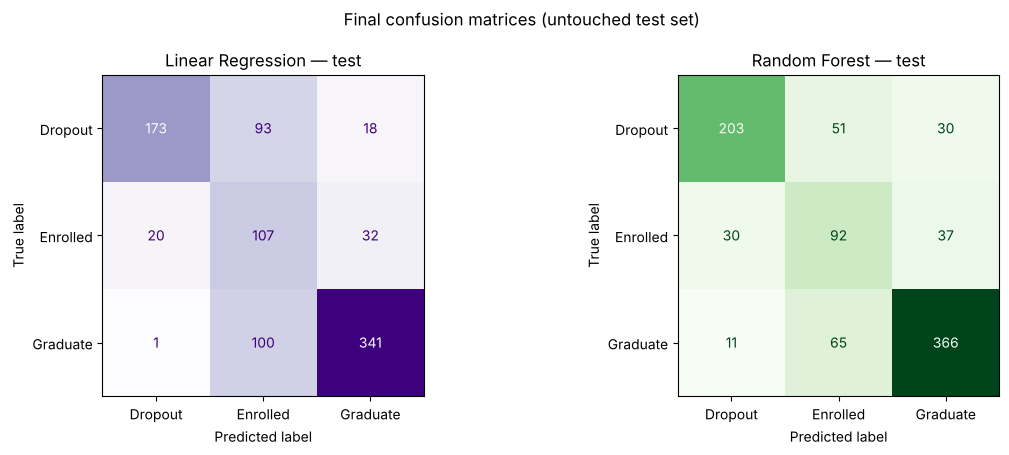

Random Forest — classification report (test set):

              precision    recall  f1-score   support

     Dropout     0.8320    0.7148    0.7689       284
    Enrolled     0.4423    0.5786    0.5014       159
    Graduate     0.8453    0.8281    0.8366       442

    accuracy                         0.7469       885
   macro avg     0.7065    0.7072    0.7023       885
weighted avg     0.7686    0.7469    0.7546       885



In [ ]:

# Confusion matrices on the test set, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(y_test, lr_test_pred, labels=CLASSES,
                                        cmap="Purples", ax=axes[0], colorbar=False)
axes[0].set_title("Linear Regression — test")
ConfusionMatrixDisplay.from_predictions(y_test, rf_test_pred, labels=CLASSES,
                                        cmap="Greens", ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest — test")
plt.suptitle("Final confusion matrices (untouched test set)")
plt.tight_layout(); plt.show()

print("Random Forest — classification report (test set):\n")
print(classification_report(y_test, rf_test_pred, labels=CLASSES, digits=4))

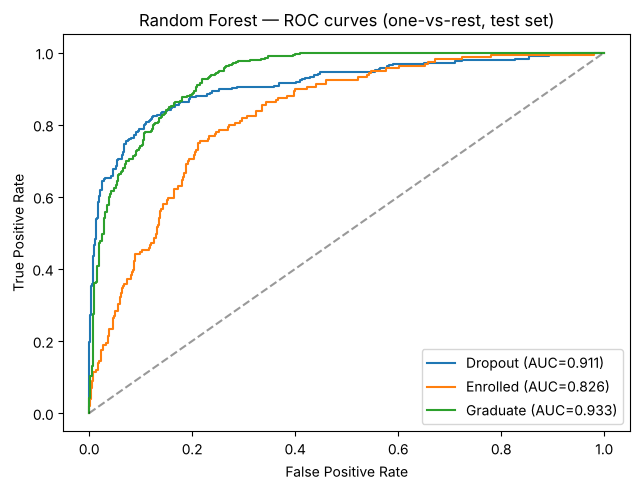

In [ ]:
# Per-class ROC curves (one-vs-rest) for the Random Forest on the test set
y_test_bin = label_binarize(y_test, classes=CLASSES)
fig, ax = plt.subplots(figsize=(6.5, 5))
for i, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], rf_test_proba[:, i])
    ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Random Forest — ROC curves (one-vs-rest, test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 6.4 Early-warning operating point — Dropout vs rest (Lab 8: threshold, ROC & PR) · *lahiru*

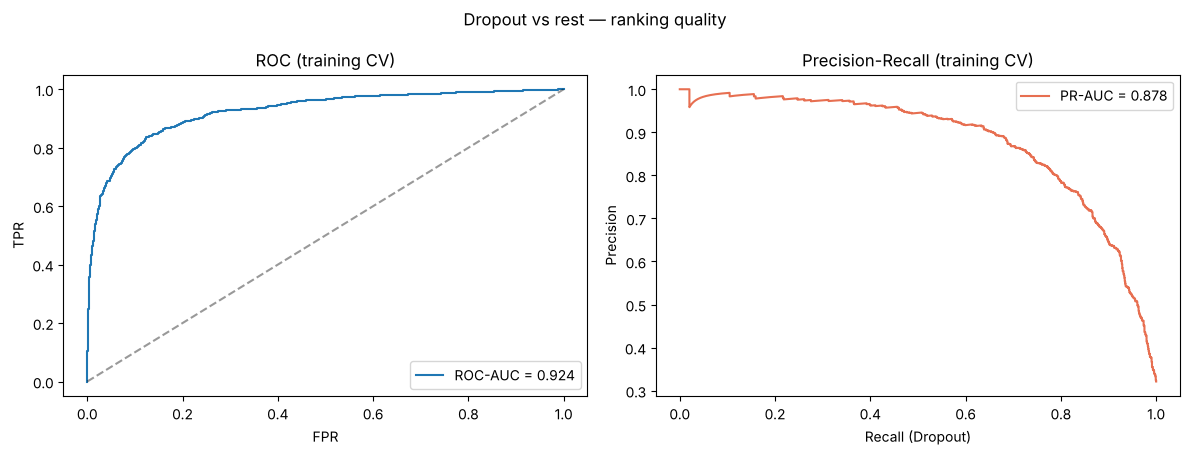

Threshold trade-off (Dropout vs rest, training CV):


,threshold,precision,recall (dropout caught),f1
0,0.3,0.6507,0.8980,0.7546
1,0.5,0.7916,0.7951,0.7933
2,0.7,0.9028,0.6535,0.7582


In [ ]:
# For an early-warning system the key question is "will this student drop out?" — a binary problem
# where PR-AUC and the decision threshold matter (Lab 8). Threshold analysis is done on the TRAINING
# set via out-of-fold probabilities; the test set is used once at the end.
yb_train = (y_train == "Dropout").astype(int)
yb_test = (y_test == "Dropout").astype(int)
rf_bin = build_pipeline(best_forest(), variant="all")

oof_proba = cross_val_predict(rf_bin, X_train, yb_train, cv=cv, method="predict_proba")[:, 1]

# ROC and PR curves on the training CV probabilities
fpr, tpr, _ = roc_curve(yb_train, oof_proba); roc_auc_cv = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(yb_train, oof_proba); pr_auc_cv = auc(rec, prec)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_cv:.3f}"); axes[0].plot([0,1],[0,1],"k--",alpha=.4)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC (training CV)"); axes[0].legend(loc="lower right")
axes[1].plot(rec, prec, color="#e76f51", label=f"PR-AUC = {pr_auc_cv:.3f}")
axes[1].set_xlabel("Recall (Dropout)"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall (training CV)"); axes[1].legend()
plt.suptitle("Dropout vs rest — ranking quality"); plt.tight_layout(); plt.show()

# Threshold experiment (training CV): lower threshold catches more dropouts (higher recall)
rows = []
for t in [0.30, 0.50, 0.70]:
    pred = (oof_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(yb_train, pred, zero_division=0),
                 "recall (dropout caught)": recall_score(yb_train, pred, zero_division=0),
                 "f1": f1_score(yb_train, pred, zero_division=0)})
print("Threshold trade-off (Dropout vs rest, training CV):")
display(pd.DataFrame(rows).round(4))

Dropout vs rest — FINAL test set
  ROC-AUC : 0.9150
  PR-AUC  : 0.8720
  Recall (dropouts caught) : 0.8134
  Precision                : 0.8021


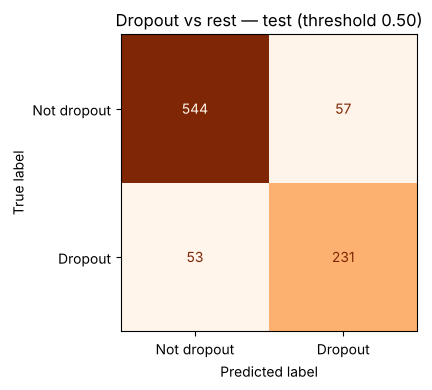

In [ ]:
# Final, single evaluation on the untouched test set (threshold 0.50)
rf_bin.fit(X_train, yb_train)
test_proba = rf_bin.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.50).astype(int)
print("Dropout vs rest — FINAL test set")
print(f"  ROC-AUC : {roc_auc_score(yb_test, test_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(yb_test, test_proba):.4f}")
print(f"  Recall (dropouts caught) : {recall_score(yb_test, test_pred):.4f}")
print(f"  Precision                : {precision_score(yb_test, test_pred):.4f}")
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(yb_test, test_pred,
                                        display_labels=["Not dropout", "Dropout"], cmap="Oranges",
                                        ax=ax, colorbar=False)
ax.set_title("Dropout vs rest — test (threshold 0.50)"); plt.tight_layout(); plt.show()

### 6.5 Is the gap reliable? cross-validated stability· *Lahiru*

A single test split gives one number, which could be a lucky or unlucky draw the lecture's own example is the *same* model scoring 86% / 79% / 83% on different splits. The lecture-note remedy is **k-fold cross-validation**: score each model on the five stratified folds and read the **mean ± standard deviation**. If the Random Forest beats Linear Regression in
*every* fold and the mean gap is larger than the fold-to-fold spread, the advantage is **consistent**, not a one-split artefact the same reasoning the notes use to prefer cross-validation over a single hold-out.

,fold,Linear Regression macro-F1,Random Forest macro-F1,RF - LR
0,1,0.6871,0.7277,0.0406
1,2,0.6675,0.7302,0.0627
2,3,0.6771,0.7427,0.0656
3,4,0.6629,0.6981,0.0352
4,5,0.6611,0.7167,0.0555


Linear Regression : mean macro-F1 = 0.6711  (std 0.0097)
Random Forest     : mean macro-F1 = 0.7231  (std 0.0150)
Random Forest wins 5 of 5 folds | mean gap = 0.0519 | fold-to-fold std of the gap = 0.0134


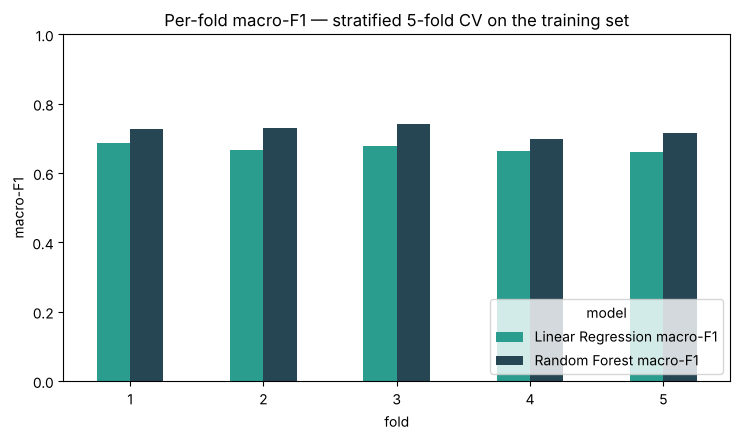

In [ ]:
from sklearn.base import clone

# Score both models on the SAME five stratified folds (Lab 8: k-fold reduces single-split luck).
rf_pipe = build_pipeline(best_forest(), variant="all")
rf_folds, lr_folds = [], []
for tr, va in cv.split(X_train, y_train):
    # Model 2 — Random Forest
    rf = clone(rf_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
    rf_folds.append(f1_score(y_train.iloc[va], rf.predict(X_train.iloc[va]), average="macro"))
    # Model 1 — Linear Regression (ordinal score -> round), fit on the regression target
    lr = build_pipeline(LinearRegression(), variant="all").fit(X_train.iloc[tr], y_train_reg.iloc[tr])
    lr_folds.append(f1_score(y_train.iloc[va], score_to_label(lr.predict(X_train.iloc[va])), average="macro"))

folds_df = pd.DataFrame({"fold": range(1, 6),
                         "Linear Regression macro-F1": lr_folds,
                         "Random Forest macro-F1": rf_folds})
folds_df["RF - LR"] = folds_df["Random Forest macro-F1"] - folds_df["Linear Regression macro-F1"]
display(folds_df.round(4))

print(f"Linear Regression : mean macro-F1 = {np.mean(lr_folds):.4f}  (std {np.std(lr_folds):.4f})")
print(f"Random Forest     : mean macro-F1 = {np.mean(rf_folds):.4f}  (std {np.std(rf_folds):.4f})")
wins = int(np.sum(np.array(rf_folds) > np.array(lr_folds)))
print(f"Random Forest wins {wins} of 5 folds | mean gap = {folds_df['RF - LR'].mean():.4f} "
      f"| fold-to-fold std of the gap = {folds_df['RF - LR'].std():.4f}")

ax = folds_df.set_index("fold")[["Linear Regression macro-F1", "Random Forest macro-F1"]].plot(
    kind="bar", figsize=(7.5, 4.5), color=["#2a9d8f", "#264653"])
ax.set_title("Per-fold macro-F1 — stratified 5-fold CV on the training set")
ax.set_xlabel("fold"); ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1)
ax.set_xticklabels(range(1, 6), rotation=0); ax.legend(title="model", loc="lower right")
plt.tight_layout(); plt.show()

### 6.6 Final takeaways & conclusion · *Lahiru, Kusal*

**Which model is more accurate for this dataset and is the gap reliable?** On the untouched test set the **Random Forest (Model 2)** leads on every imbalance-aware metric — macro-F1 ≈ 0.70, balanced accuracy ≈ 0.71 and MCC ≈ 0.60  against the best Linear-Regression route (polynomial: macro-F1 ≈ 0.67). Crucially this is **not just a lucky split**: in the stratified
5-fold cross-validation (6.5) the Random Forest's macro-F1 is higher in **every fold**, and the mean gap is larger than the fold-to-fold spread. So the Random Forest is the **more accurate model for this dataset**, consistently across folds not only on one test draw.

**Does it match this scenario?** The task is an **imbalanced 3-class** problem whose practical goal is an **early-warning system for dropout**, where the middle `Enrolled` class is rare. That makes raw accuracy the wrong headline the indicator Linear-Regression route reaches the highest accuracy yet collapses on `Enrolled` (the *accuracy trap*) — and makes
**macro-F1, balanced accuracy, MCC and per-class recall** the right lens. On those, and on per-class F1, the Random Forest fits the scenario best: it is the most balanced across all three outcomes and the only model giving class probabilities (ROC-AUC ≈ 0.89) for tuning the dropout-alarm threshold (6.4).

Appropriate metrics over accuracy (confusion matrix, precision, recall, F1 / macro-F1, MCC, ROC-AUC and PR-AUC); the **same stratified 5-fold CV splits, one leak-safe pipeline, and
identical metrics** for a fair comparison; the **test set used only once**; class imbalance studied with SMOTE and class weights (6.2); the decision threshold analysed (6.4); and the final gap **checked for consistency across folds** (5-fold CV, 6.5) rather than asserted.

**How the accuracy could be improved (critical analysis).** A **native classifier** for Model 1 (logistic / softmax regression) for class probabilities and no masking; **class weighting / SMOTE with per-class threshold tuning** to lift `Enrolled` recall; **gradient-boosted trees** (Gradient Boosting / XGBoost), which usually top a random forest on tabular
data; richer feature engineering with filter / wrapper / embedded selection; and a wider **grid or random hyperparameter search** for a better-tuned forest.

**Limitations.** Moderate imbalance caps `Enrolled` recall; registry codes are modelled as encoded categories; the strongest predictors are second-semester results, so the model is most useful as an **end-of-first-year** early-warning tool; and results reflect one institution and period (possible drift).

**Conclusion.** Comparing two distinct classical algorithms under one fair, leakage-safe protocol, the **Random Forest is the recommended, more accurate model** for predicting student dropout and academic success on this dataset  a verdict supported by the imbalance-aware metrics and by consistent per-fold cross-validation with Linear Regression retained as a
transparent, interpretable baseline.